# Projeto SIM - Grupo 02 (Carregamento e Preparação de Dados - PC2)

**Fonte Oficial dos Dados:** Ministério da Saúde / DATASUS (`ftp://ftp.datasus.gov.br`)  
**Unidade Federativa:** Bahia (BA) | **Período de Análise:** 2022 a 2025

### 1. Origem, Diretórios do Servidor e Status dos Dados
Todos os microdados e tabelas auxiliares são extraídos diretamente do servidor FTP oficial do DATASUS durante a execução deste notebook, garantindo total reprodutibilidade sem necessidade de upload manual de arquivos:

* **`DOBA2022.dbc`** — Diretório FTP: `/dissemin/publicos/SIM/CID10/DORES` *(Dados Definitivos - 2022)*
* **`DOBA2023.dbc`** — Diretório FTP: `/dissemin/publicos/SIM/CID10/DORES` *(Dados Definitivos - 2023)*
* **`DOBA2024.dbc`** — Diretório FTP: `/dissemin/publicos/SIM/CID10/DORES` *(Dados Definitivos - 2024)*
* **`DOBA2025.dbc`** — Diretório FTP: `/dissemin/publicos/SIM/PRELIM/DORES` *(**Dados Preliminares** - 2025, sujeitos a revisão pelo Ministério da Saúde)*
* **Documentação Oficial (Dicionário):** Diretório FTP: `/dissemin/publicos/SIM/CID10/DOCS` (Estrutura do SIM distribuída pelo DATASUS).
* **Base Territorial (Regiões de Saúde - M3):** Diretório FTP: `/territorio/tabelas/2026`, contendo o arquivo (`06-base_territorial_jun26`), este arquivo contém o relacionamento entre municípios (`rl_municip_regsaud.dbf`) e as 28 Regiões de Saúde da Bahia (`tb_regsaud.dbf`).

*(Nota: As datas exatas de última modificação/atualização de cada arquivo no servidor do DATASUS são consultadas via protocolo FTP e exibidas automaticamente na Célula 3).*

In [ ]:
!pip install -q pyreaddbc dbfread pandas

import ftplib
import os
import zipfile
import glob
import shutil
from datetime import datetime
import pandas as pd
from pyreaddbc import dbc2dbf
from dbfread import DBF
from google.colab import drive

# 1. Montar o Google Drive para salvar os artefatos para o PC3
drive.mount('/content/drive')

PASTA_DRIVE = '/content/drive/MyDrive/Drive-Grupo02'
os.makedirs(PASTA_DRIVE, exist_ok=True)
print(f"Diretório de exportação no Google Drive configurado: {PASTA_DRIVE}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Diretório de exportação no Google Drive configurado: /content/drive/MyDrive/Drive-Grupo02


In [ ]:
arquivos_alvo = [
    {'nome': 'DOBA2022.dbc', 'ano': '2022', 'pasta': '/dissemin/publicos/SIM/CID10/DORES', 'status': 'Definitivo'},
    {'nome': 'DOBA2023.dbc', 'ano': '2023', 'pasta': '/dissemin/publicos/SIM/CID10/DORES', 'status': 'Definitivo'},
    {'nome': 'DOBA2024.dbc', 'ano': '2024', 'pasta': '/dissemin/publicos/SIM/CID10/DORES', 'status': 'Definitivo'},
    {'nome': 'DOBA2025.dbc', 'ano': '2025', 'pasta': '/dissemin/publicos/SIM/PRELIM/DORES', 'status': 'Preliminar'}
]

SALVAR_CSV_BRUTO_INDIVIDUAL = True

ftp = ftplib.FTP('ftp.datasus.gov.br', timeout=60)
ftp.login()

lista_dfs = []
metadados_arquivos = []

print("1. Baixando microdados do SIM no FTP do DATASUS (Leitura Única)...")
for arq in arquivos_alvo:
    nome_dbc = arq['nome']
    pasta_ftp = arq['pasta']
    nome_dbf = nome_dbc.replace('.dbc', '.dbf')

    ftp.cwd(pasta_ftp)

    # Captura a data de atualização oficial do arquivo no servidor FTP
    try:
        resp_mdtm = ftp.sendcmd(f'MDTM {nome_dbc}')
        codigo_data = resp_mdtm.split()[1]
        data_atualizacao = datetime.strptime(codigo_data[:8], '%Y%m%d').strftime('%d/%m/%Y')
    except Exception:
        data_atualizacao = "Verificada no FTP"

    print(f" -> Baixando {nome_dbc} ({arq['status']} | Atualizado em: {data_atualizacao})...")
    with open(nome_dbc, 'wb') as f:
        ftp.retrbinary(f'RETR {nome_dbc}', f.write)

    dbc2dbf(nome_dbc, nome_dbf)
    tabela = DBF(nome_dbf, encoding='iso-8859-1', load=True)

    df_temp = pd.DataFrame(iter(tabela)).astype(str)
    df_temp.columns = df_temp.columns.str.strip().str.upper()

    if SALVAR_CSV_BRUTO_INDIVIDUAL:
        nome_csv_ind = nome_dbc.replace('.dbc', '_bruto.csv')
        df_temp.to_csv(nome_csv_ind, index=False, sep=',', encoding='utf-8')

    # Registra o ano do arquivo e o ano extraído da data do óbito
    df_temp['ANO_ARQUIVO'] = arq['ano']
    df_temp['ANO_OBITO'] = df_temp['DTOBITO'].str[-4:]

    metadados_arquivos.append({
        'Arquivo': nome_dbc,
        'Diretório FTP': pasta_ftp,
        'Status': arq['status'],
        'Última Atualização': data_atualizacao,
        'Linhas Brutas': df_temp.shape[0],
        'Colunas Originais': df_temp.shape[1] - 2
    })

    lista_dfs.append(df_temp)
    os.remove(nome_dbc)
    os.remove(nome_dbf)

df_bruto = pd.concat(lista_dfs, ignore_index=True)

print("\nResumo de Origem e Atualização dos Arquivos:")
display(pd.DataFrame(metadados_arquivos))

# Validação rigorosa da base bruta (423.233 registros)
total_bruto = df_bruto.shape[0]
print(f"\nTotal de registros brutos consolidados: {total_bruto}")
assert total_bruto == 423233, f"ERRO DE VALIDAÇÃO: Esperado 423.233 registros brutos, mas foram encontrados {total_bruto}."

# Cálculo do preenchimento sobre a BASE BRUTA (para bater com a ficha técnica)
print("Calculando resumo de preenchimento sobre os arquivos brutos...")
colunas_originais = [c for c in df_bruto.columns if c not in ['ANO_ARQUIVO', 'ANO_OBITO']]
preenchimento_bruto = (df_bruto[colunas_originais].replace(['', 'None', 'nan', 'NaN'], pd.NA).notna().mean() * 100).round(2)
preenchimento_bruto.to_csv('resumo_preenchimento.csv', header=['PREENCHIMENTO_PERCENTUAL'])
shutil.copy('resumo_preenchimento.csv', os.path.join(PASTA_DRIVE, 'resumo_preenchimento.csv'))

# 2. Download do Dicionário Oficial na pasta /dissemin/publicos/SIM/CID10/DOCS
print("\n2. Baixando Dicionário/Estrutura oficial no FTP (/dissemin/publicos/SIM/CID10/DOCS)...")
ftp.cwd('/dissemin/publicos/SIM/CID10/DOCS')
arquivos_docs = ftp.nlst()

nome_doc_alvo = 'Estrutura_do_SIM_2025.pdf'

# Localiza o arquivo exato ignorando diferenças de maiúsculas/minúsculas no servidor FTP
encontrados = [f for f in arquivos_docs if f.lower() == nome_doc_alvo.lower()]

if encontrados:
    nome_doc_ftp = encontrados[0]
else:
    # Fallback seguro: busca apenas arquivos que contenham 'ESTRUTURA' no nome
    candidatos_estrutura = [f for f in arquivos_docs if 'ESTRUTURA' in f.upper()]
    nome_doc_ftp = sorted(candidatos_estrutura)[-1] if candidatos_estrutura else nome_doc_alvo

with open(nome_doc_ftp, 'wb') as f:
    ftp.retrbinary(f'RETR {nome_doc_ftp}', f.write)

shutil.copy(nome_doc_ftp, os.path.join(PASTA_DRIVE, nome_doc_ftp))
print(f" -> Documento oficial baixado com seu nome original: {nome_doc_ftp}")

# 3. Download e extração direta da Base Territorial oficial no FTP
pasta_territorial = '/territorio/tabelas/2026'
arquivo_zip_territorial = '06-base_territorial_jun26.zip'
tabelas_necessarias = ['rl_municip_regsaud.dbf', 'tb_regsaud.dbf']

print(f"\n3. Baixando Base Territorial de {pasta_territorial}/{arquivo_zip_territorial}...")
ftp.cwd(pasta_territorial)

# Caso o nome no servidor tenha alguma variação de maiúsculas/minúsculas, localiza o arquivo exato
arquivos_no_ftp = ftp.nlst()
if arquivo_zip_territorial not in arquivos_no_ftp:
    candidatos_zip = [f for f in arquivos_no_ftp if 'base_territorial' in f.lower() and f.lower().endswith('.zip')]
    if candidatos_zip:
        arquivo_zip_territorial = candidatos_zip[0]

with open(arquivo_zip_territorial, 'wb') as f:
    ftp.retrbinary(f'RETR {arquivo_zip_territorial}', f.write)

ftp.quit()

# Extrai apenas os dois arquivos .dbf necessários (independente de estarem em subpastas dentro do .zip)
print(f" -> Extraindo {tabelas_necessarias} de {arquivo_zip_territorial}...")
with zipfile.ZipFile(arquivo_zip_territorial, 'r') as z:
    for membro in z.namelist():
        nome_base = os.path.basename(membro).lower()
        if nome_base in tabelas_necessarias:
            with open(nome_base, 'wb') as out_f:
                out_f.write(z.read(membro))
            # Salva uma cópia de segurança na pasta do Google Drive
            shutil.copy(nome_base, os.path.join(PASTA_DRIVE, nome_base))
            print(f" -> '{nome_base}' extraído com sucesso!")

# Remove o .zip temporário para manter o Colab limpo
os.remove(arquivo_zip_territorial)

assert os.path.exists('rl_municip_regsaud.dbf') and os.path.exists('tb_regsaud.dbf'), (
    "ERRO CRÍTICO: As tabelas 'rl_municip_regsaud.dbf' e 'tb_regsaud.dbf' não foram encontradas dentro do .zip."
)
print("✅ Etapa de download e validação bruta concluída com sucesso!")

1. Baixando microdados do SIM no FTP do DATASUS (Leitura Única)...
 -> Baixando DOBA2022.dbc (Definitivo | Atualizado em: 21/12/2023)...
 -> Baixando DOBA2023.dbc (Definitivo | Atualizado em: 19/12/2024)...
 -> Baixando DOBA2024.dbc (Definitivo | Atualizado em: 23/12/2025)...
 -> Baixando DOBA2025.dbc (Preliminar | Atualizado em: 28/08/2026)...

Resumo de Origem e Atualização dos Arquivos:


,Arquivo,Diretório FTP,Status,Última Atualização,Linhas Brutas,Colunas Originais
0,DOBA2022.dbc,/dissemin/publicos/SIM/CID10/DORES,Definitivo,21/12/2023,107641,87
1,DOBA2023.dbc,/dissemin/publicos/SIM/CID10/DORES,Definitivo,19/12/2024,103081,87
2,DOBA2024.dbc,/dissemin/publicos/SIM/CID10/DORES,Definitivo,23/12/2025,106212,87
3,DOBA2025.dbc,/dissemin/publicos/SIM/PRELIM/DORES,Preliminar,28/08/2026,106299,87



Total de registros brutos consolidados: 423233
Calculando resumo de preenchimento sobre os arquivos brutos...

2. Baixando Dicionário/Estrutura oficial no FTP (/dissemin/publicos/SIM/CID10/DOCS)...
 -> Documento oficial baixado com seu nome original: Estrutura_do_SIM_2025.pdf

3. Baixando Base Territorial de /territorio/tabelas/2026/06-base_territorial_jun26.zip...
 -> Extraindo ['rl_municip_regsaud.dbf', 'tb_regsaud.dbf'] de 06-base_territorial_jun26.zip...
 -> 'tb_regsaud.dbf' extraído com sucesso!
 -> 'rl_municip_regsaud.dbf' extraído com sucesso!
✅ Etapa de download e validação bruta concluída com sucesso!


In [ ]:
print("1. Aplicando recortes definidos na ficha técnica...")

assert (df_bruto['ANO_OBITO'] == df_bruto['ANO_ARQUIVO']).all(), "ERRO: ANO_OBITO diverge do ANO_ARQUIVO!"

# Recorte 1: Manter apenas residentes da Bahia (códigos iniciados em 29)
df_estudo = df_bruto[df_bruto['CODMUNRES'].str.startswith('29', na=False)].copy()

# Recorte 2: Excluir óbitos com idade ignorada e menores de 1 ano
df_estudo = df_estudo[df_estudo['IDADE'].str.match('^[45]', na=False)].copy()

# Recorte 3: Criar a Variável-Alvo (Causas Externas = capítulos V, W, X, Y da CID-10)
df_estudo['ALVO_CAUSA_EXTERNA'] = df_estudo['CAUSABAS'].str[0].isin(['V', 'W', 'X', 'Y']).astype(int)

# Validação rigorosa de linhas após filtragem (412.692 linhas)
linhas_filtradas = df_estudo.shape[0]
print(f" -> Registros após filtros da ficha técnica: {linhas_filtradas}")
assert linhas_filtradas == 412692, f"ERRO: Esperado exatamente 412.692 linhas, mas obteve {linhas_filtradas}."

# Validação rigorosa do total de Causas Externas (53.800 óbitos)
total_alvo = df_estudo['ALVO_CAUSA_EXTERNA'].sum()
prop_alvo = (total_alvo / linhas_filtradas * 100).round(2)
print(f" -> Total de Causas Externas (ALVO = 1): {total_alvo} ({prop_alvo}%)")
assert total_alvo == 53800, f"ERRO: Esperado 53.800 causas externas, mas obteve {total_alvo}."

print("\n2. Integrando Regiões de Saúde (Conjunto M3)...")

tab_municipio = DBF('rl_municip_regsaud.dbf', encoding='iso-8859-1', load=True)
df_municipios = pd.DataFrame(iter(tab_municipio)).astype(str)
df_municipios.columns = df_municipios.columns.str.strip().str.upper()

tab_regiao = DBF('tb_regsaud.dbf', encoding='iso-8859-1', load=True)
df_regioes = pd.DataFrame(iter(tab_regiao)).astype(str)
df_regioes.columns = df_regioes.columns.str.strip().str.upper()

# Identifica dinamicamente a coluna de nome da região na tb_regsaud (evita erro caso não se chame DS_NOME)
colunas_nome_candidatas = [c for c in df_regioes.columns if c != 'CO_REGSAUD' and any(k in c for k in ['NOME', 'DS_', 'NO_', 'DESC', 'REG'])]
col_nome_regiao = colunas_nome_candidatas[0] if colunas_nome_candidatas else [c for c in df_regioes.columns if c != 'CO_REGSAUD'][0]
print(f" -> Coluna de nome da região identificada em tb_regsaud: '{col_nome_regiao}'")

# Padroniza chave de 6 dígitos do município e REMOVE DUPLICATAS antes do merge para não duplicar óbitos
df_municipios['MUNICIPIO_6'] = df_municipios['CO_MUNICIP'].str.strip().str[:6]
df_municipios = df_municipios[['MUNICIPIO_6', 'CO_REGSAUD']].drop_duplicates(subset=['MUNICIPIO_6'])

df_regioes['CO_REGSAUD'] = df_regioes['CO_REGSAUD'].str.strip()
df_regioes = df_regioes[['CO_REGSAUD', col_nome_regiao]].drop_duplicates(subset=['CO_REGSAUD'])

df_estudo['CODMUNRES_6'] = df_estudo['CODMUNRES'].str.strip().str[:6]

# 1º Merge: Município -> Código da Região de Saúde
df_estudo = df_estudo.merge(
    df_municipios,
    left_on='CODMUNRES_6',
    right_on='MUNICIPIO_6',
    how='left'
)

# 2º Merge: Código da Região -> Nome da Região de Saúde (NO_REGSAUD)
df_estudo = df_estudo.merge(
    df_regioes,
    on='CO_REGSAUD',
    how='left'
).rename(columns={col_nome_regiao: 'NO_REGSAUD'})

df_estudo = df_estudo.drop(columns=['MUNICIPIO_6', 'CODMUNRES_6', 'CO_REGSAUD'])

# Validações pós-merge exigidas pela revisão:
assert df_estudo.shape[0] == 412692, f"ERRO PÓS-MERGE: O número de linhas mudou para {df_estudo.shape[0]}!"
assert 'NO_REGSAUD' in df_estudo.columns, "ERRO: A coluna NO_REGSAUD não foi criada!"

qtd_regioes = df_estudo['NO_REGSAUD'].dropna().nunique()
sem_regiao = df_estudo['NO_REGSAUD'].isna().sum()
cod_290000 = (df_estudo['CODMUNRES'].str[:6] == '290000').sum()

print(f" -> Total de Regiões de Saúde distintas mapeadas na Bahia: {qtd_regioes}")
print(f" -> Óbitos sem região associada: {sem_regiao} (Óbitos com município ignorado '290000': {cod_290000} — tratamento ficará para o PC3)")

assert qtd_regioes == 28, f"ERRO: Esperadas as 28 Regiões de Saúde da Bahia, mas foram encontradas {qtd_regioes}."
print("✅ Cruzamento territorial concluído e validado com sucesso!")

1. Aplicando recortes definidos na ficha técnica...
 -> Registros após filtros da ficha técnica: 412692
 -> Total de Causas Externas (ALVO = 1): 53800 (13.04%)

2. Integrando Regiões de Saúde (Conjunto M3)...
 -> Coluna de nome da região identificada em tb_regsaud: 'DS_NOME'
 -> Total de Regiões de Saúde distintas mapeadas na Bahia: 28
 -> Óbitos sem região associada: 532 (Óbitos com município ignorado '290000': 532 — tratamento ficará para o PC3)
✅ Cruzamento territorial concluído e validado com sucesso!


In [ ]:
colunas_estudo = [
    'ANO_OBITO',          # Ano extraído de DTOBITO (Controle temporal)
    'CODMUNRES',          # Código IBGE do Município de Residência (6 dígitos)
    'NO_REGSAUD',         # M3: Nome da Região de Saúde (28 regiões da Bahia)
    'IDADE',              # M1: Idade codificada padrão SIM
    'SEXO',               # M1: Sexo
    'RACACOR',            # M2: Raça/Cor
    'ESTCIV',             # M2: Situação Conjugal
    'ESC2010',            # M2: Escolaridade (padrão 2010)
    'CAUSABAS',           # CID-10 da Causa Básica (conferência)
    'ALVO_CAUSA_EXTERNA'  # Variável-Alvo binária (1 = Capítulo XX - Causas Externas; 0 = Demais)
]

# Validação extra do ANO_OBITO conforme PC3 (feita antes de remover ANO_ARQUIVO)
if 'ANO_ARQUIVO' in df_estudo.columns:
    assert (df_estudo['ANO_OBITO'] == df_estudo['ANO_ARQUIVO']).all(), "ERRO: ANO_OBITO diverge do ANO_ARQUIVO em alguns registros!"

df_estudo = df_estudo[colunas_estudo]

print("=" * 75)
print("RELATÓRIO DE DIMENSÕES E ESTRUTURA DAS BASES (ETAPA 4 - PC2)")
print("=" * 75)

# Exibe o resumo de preenchimento bruto calculado anteriormente
print("\n• Resumo de Preenchimento da Base Bruta (Ficha Técnica):")
# Filtramos apenas as colunas de interesse do quadro 3 da ficha técnica para visualização
vars_ficha = ['RACACOR', 'ESC2010', 'ESTCIV', 'CIRCOBITO', 'ATESTANTE']
if 'preenchimento_bruto' in locals():
    display(preenchimento_bruto.loc[preenchimento_bruto.index.isin(vars_ficha)])

# 1. Dimensões da base bruta vs. base do estudo
qtd_cols_originais = df_bruto.shape[1] - 2  # Desconta ANO_ARQUIVO e ANO_OBITO adicionados na leitura
print(f"\n• Dimensões da Base Bruta (2022-2025):     {df_bruto.shape[0]:,} linhas x {qtd_cols_originais} colunas originais ({df_bruto.shape[1]} com colunas auxiliares)")
print(f"• Dimensões da Base de Estudo (Filtrada):  {df_estudo.shape[0]:,} linhas x {df_estudo.shape[1]} colunas")

# 2. Lista de atributos com seus tipos e descrições (Item 3 da Etapa 4)
descricoes_atributos = {
    'ANO_OBITO': 'Controle Temporal — Ano extraído da data do óbito (DTOBITO)',
    'CODMUNRES': 'Territorial — Código IBGE (6 dígitos) do município de residência na Bahia',
    'NO_REGSAUD': 'Conjunto M3 — Nome da Região de Saúde da Bahia (28 regiões)',
    'IDADE': 'Conjunto M1 — Idade codificada do falecido (primeiro dígito 4=anos, 5=mais de 100 anos)',
    'SEXO': 'Conjunto M1 — Sexo do falecido',
    'RACACOR': 'Conjunto M2 — Raça/Cor',
    'ESTCIV': 'Conjunto M2 — Situação Conjugal',
    'ESC2010': 'Conjunto M2 — Escolaridade (padrão 2010)',
    'CAUSABAS': 'Controle — Código CID-10 da causa básica do óbito (A ser removido para ML)',
    'ALVO_CAUSA_EXTERNA': 'Variável-Alvo — Causa Externa (1 = Capítulo XX [V01-Y98]; 0 = Outras causas)'
}

# Tratamento de nulos/vazios para a contagem correta na tabela de atributos
df_estudo_na = df_estudo.replace(['', ' ', 'None', 'nan', 'NaN'], pd.NA)
df_estudo_na['RACACOR'] = df_estudo_na['RACACOR'].replace('9', pd.NA)
df_estudo_na['ESC2010'] = df_estudo_na['ESC2010'].replace('9', pd.NA)
df_estudo_na['ESTCIV'] = df_estudo_na['ESTCIV'].replace('9', pd.NA)
df_estudo_na['SEXO'] = df_estudo_na['SEXO'].replace(['0', '9', 'I'], pd.NA)
df_estudo_na['CODMUNRES'] = df_estudo_na['CODMUNRES'].replace('290000', pd.NA)

tabela_atributos = pd.DataFrame({
    'Atributo': df_estudo.columns,
    'Tipo no Pandas (dtype)': [str(df_estudo[c].dtype) for c in df_estudo.columns],
    'Não-Nulos': [df_estudo_na[c].notna().sum() for c in df_estudo.columns],
    'Papel / Descrição no Estudo': [descricoes_atributos[c] for c in df_estudo.columns]
})
print("\n• Lista de Atributos da Base de Estudo e seus Tipos (Item 3 da Etapa 4):")
display(tabela_atributos)

# 3. Contagem de óbitos por ano (Bruta vs. Estudo)
contagem_ano = pd.DataFrame({
    'Registros na Base Bruta': df_bruto['ANO_ARQUIVO'].value_counts().sort_index(),
    'Registros na Base de Estudo': df_estudo['ANO_OBITO'].value_counts().sort_index(),
    'Causas Externas (Alvo = 1)': df_estudo.groupby('ANO_OBITO')['ALVO_CAUSA_EXTERNA'].sum(),
    '% Causas Externas': (df_estudo.groupby('ANO_OBITO')['ALVO_CAUSA_EXTERNA'].mean() * 100).round(2)
})
print("\n• Contagem de Registros por Ano:")
display(contagem_ano)

# CUIDADO PC3: Remover CAUSABAS antes de salvar para evitar vazamento de dados
df_estudo_export = df_estudo.drop(columns=['CAUSABAS'])
print(f"\n• Dimensões da Base Exportada (Sem CAUSABAS): {df_estudo_export.shape[0]:,} linhas x {df_estudo_export.shape[1]} colunas")

# 4. Exportação padronizada (separador ',' e nome sim_BA_2022_2025_base_estudo.csv.gz)
nome_arquivo_final = 'sim_BA_2022_2025_base_estudo.csv.gz'
caminho_drive_final = os.path.join(PASTA_DRIVE, nome_arquivo_final)

print(f"\nExportando '{nome_arquivo_final}' (separador=',')...")
df_estudo_export.to_csv(nome_arquivo_final, index=False, sep=',', encoding='utf-8', compression='gzip')
shutil.copy(nome_arquivo_final, caminho_drive_final)

print(f"✅ Arquivo salvo localmente no Colab: /content/{nome_arquivo_final}")
print(f"✅ Cópia persistente salva no Google Drive: {caminho_drive_final}")

RELATÓRIO DE DIMENSÕES E ESTRUTURA DAS BASES (ETAPA 4 - PC2)

• Resumo de Preenchimento da Base Bruta (Ficha Técnica):


,0
RACACOR,96.84
ESTCIV,94.48
ESC2010,92.82
CIRCOBITO,12.81
ATESTANTE,89.15



• Dimensões da Base Bruta (2022-2025):     423,233 linhas x 87 colunas originais (89 com colunas auxiliares)
• Dimensões da Base de Estudo (Filtrada):  412,692 linhas x 10 colunas

• Lista de Atributos da Base de Estudo e seus Tipos (Item 3 da Etapa 4):


,Atributo,Tipo no Pandas (dtype),Não-Nulos,Papel / Descrição no Estudo
0,ANO_OBITO,object,412692,Controle Temporal — Ano extraído da data do ób...
1,CODMUNRES,object,412160,Territorial — Código IBGE (6 dígitos) do munic...
2,NO_REGSAUD,object,412160,Conjunto M3 — Nome da Região de Saúde da Bahia...
3,IDADE,object,412692,Conjunto M1 — Idade codificada do falecido (pr...
4,SEXO,object,412667,Conjunto M1 — Sexo do falecido
5,RACACOR,object,400671,Conjunto M2 — Raça/Cor
6,ESTCIV,object,370950,Conjunto M2 — Situação Conjugal
7,ESC2010,object,338454,Conjunto M2 — Escolaridade (padrão 2010)
8,CAUSABAS,object,412692,Controle — Código CID-10 da causa básica do ób...
9,ALVO_CAUSA_EXTERNA,int64,412692,Variável-Alvo — Causa Externa (1 = Capítulo XX...



• Contagem de Registros por Ano:


,Registros na Base Bruta,Registros na Base de Estudo,Causas Externas (Alvo = 1),% Causas Externas
2022,107641,104798,13506,12.89
2023,103081,100380,13623,13.57
2024,106212,103690,13728,13.24
2025,106299,103824,12943,12.47



• Dimensões da Base Exportada (Sem CAUSABAS): 412,692 linhas x 9 colunas

Exportando 'sim_BA_2022_2025_base_estudo.csv.gz' (separador=',')...
✅ Arquivo salvo localmente no Colab: /content/sim_BA_2022_2025_base_estudo.csv.gz
✅ Cópia persistente salva no Google Drive: /content/drive/MyDrive/Drive-Grupo02/sim_BA_2022_2025_base_estudo.csv.gz


In [ ]:
import shutil
import glob
import os

print("Copiando arquivos brutos individuais para o Google Drive...")
arquivos_brutos = glob.glob('*_bruto.csv')

if arquivos_brutos:
    for arq in arquivos_brutos:
        caminho_destino = os.path.join(PASTA_DRIVE, arq)
        shutil.copy(arq, caminho_destino)
        print(f" -> Arquivo {arq} salvo em: {caminho_destino}")
    print("\n✅ Todos os arquivos brutos individuais foram salvos no Drive com sucesso!")
else:
    print("Nenhum arquivo bruto encontrado no diretório atual.")

Copiando arquivos brutos individuais para o Google Drive...
 -> Arquivo DOBA2025_bruto.csv salvo em: /content/drive/MyDrive/Drive-Grupo02/DOBA2025_bruto.csv
 -> Arquivo DOBA2022_bruto.csv salvo em: /content/drive/MyDrive/Drive-Grupo02/DOBA2022_bruto.csv
 -> Arquivo DOBA2024_bruto.csv salvo em: /content/drive/MyDrive/Drive-Grupo02/DOBA2024_bruto.csv
 -> Arquivo DOBA2023_bruto.csv salvo em: /content/drive/MyDrive/Drive-Grupo02/DOBA2023_bruto.csv

✅ Todos os arquivos brutos individuais foram salvos no Drive com sucesso!


In [ ]:
import pandas as pd
import numpy as np

# Ajuste o caminho conforme onde os arquivos estão no seu Colab/Drive
caminho = "/content/drive/MyDrive/Drive-Grupo02/" # ou "data/" se clonou o repo

arquivos = {
    2022: f"{caminho}DOBA2022_bruto.csv",
    2023: f"{caminho}DOBA2023_bruto.csv",
    2024: f"{caminho}DOBA2024_bruto.csv",
    2025: f"{caminho}DOBA2025_bruto.csv",
}

dfs = []
for ano, arq in arquivos.items():
    # low_memory=False evita avisos de tipos misturados; dtype=str preserva códigos com zero à esquerda
    temp = pd.read_csv(arq, sep=",", dtype=str, low_memory=False)
    temp.columns = temp.columns.str.strip().str.upper()
    temp["ANO_ARQUIVO"] = ano
    dfs.append(temp)
    print(f"{ano}: {temp.shape[0]:,} linhas | {temp.shape[1]} colunas")

df_bruto = pd.concat(dfs, ignore_index=True)
print("-" * 45)
print(f"BASE CONSOLIDADA: {df_bruto.shape[0]:,} linhas | {df_bruto.shape[1]} colunas")

2022: 107,641 linhas | 88 colunas
2023: 103,081 linhas | 88 colunas
2024: 106,212 linhas | 88 colunas
2025: 106,299 linhas | 88 colunas
---------------------------------------------
BASE CONSOLIDADA: 423,233 linhas | 88 colunas


In [ ]:
print("=== RESUMO DE TIPOS E MEMÓRIA ===")
df_bruto.info(memory_usage="deep")

print("\n=== REGISTROS DUPLICADOS ===")
duplicatas = df_bruto.duplicated().sum()
print(f"Total de linhas exatamente duplicadas: {duplicatas:,} ({duplicatas/len(df_bruto)*100:.4f}%)")

=== RESUMO DE TIPOS E MEMÓRIA ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 423233 entries, 0 to 423232
Data columns (total 88 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   ORIGEM       423233 non-null  object
 1   TIPOBITO     423233 non-null  object
 2   DTOBITO      423233 non-null  object
 3   HORAOBITO    415546 non-null  object
 4   NATURAL      416581 non-null  object
 5   CODMUNNATU   415040 non-null  object
 6   DTNASC       422385 non-null  object
 7   IDADE        423233 non-null  object
 8   SEXO         423233 non-null  object
 9   RACACOR      409858 non-null  object
 10  ESTCIV       399874 non-null  object
 11  ESC          396217 non-null  object
 12  ESC2010      392834 non-null  object
 13  SERIESCFAL   67081 non-null   object
 14  OCUP         344954 non-null  object
 15  CODMUNRES    423233 non-null  object
 16  LOCOCOR      423233 non-null  object
 17  CODESTAB     277598 non-null  object
 18  ESTABDESCR

In [ ]:
nulos_qtd = df_bruto.isna().sum()
nulos_pct = (df_bruto.isna().mean() * 100).round(2)

tabela_nulos = pd.DataFrame({
    "Qtd_Nulos": nulos_qtd,
    "Pct_Nulos (%)": nulos_pct
}).sort_values(by="Pct_Nulos (%)", ascending=False)

print("=== TOP 25 COLUNAS COM MAIS VALORES AUSENTES ===")
display(tabela_nulos.head(25))

print(f"\nColunas com mais de 80% de nulos: {(tabela_nulos['Pct_Nulos (%)'] > 80).sum()}")
print(f"Colunas sem nenhum nulo: {(tabela_nulos['Pct_Nulos (%)'] == 0).sum()}")

=== TOP 25 COLUNAS COM MAIS VALORES AUSENTES ===


,Qtd_Nulos,Pct_Nulos (%)
ESTABDESCR,423233,100.00
FONTESINF,423233,100.00
NUDIASINF,423233,100.00
NUDIASOBIN,423233,100.00
CAUSAMAT,423222,100.00
CB_PRE,423233,100.00
TPRESGINFO,422679,99.87
CIRURGIA,422444,99.81
EXAME,422384,99.80
SERIESCMAE,420193,99.28



Colunas com mais de 80% de nulos: 44
Colunas sem nenhum nulo: 20


In [ ]:
# Mapeamento dos códigos de "Ignorado" conforme o dicionário do SIM
codigos_ignorado = {
    "SEXO": ["0", "9"],
    "RACACOR": ["9"],
    "ESTCIV": ["9"],
    "ESC": ["9"],
    "ESC2010": ["9"],
    "LOCOCOR": ["9"],
    "ASSISTMED": ["9"],
    "CIRCOBITO": ["9"],
}

resumo_ignorados = []
for col, cods in codigos_ignorado.items():
    if col in df_bruto.columns:
        qtd_ign = df_bruto[col].isin(cods).sum()
        qtd_nan = df_bruto[col].isna().sum()
        total_faltante = qtd_ign + qtd_nan
        resumo_ignorados.append({
            "Coluna": col,
            "Codigos_Ign": ", ".join(cods),
            "Qtd_Ignorado": qtd_ign,
            "Qtd_NaN": qtd_nan,
            "Total_Faltante (%)": round((total_faltante / len(df_bruto)) * 100, 2)
        })

df_ignorados = pd.DataFrame(resumo_ignorados).sort_values(by="Total_Faltante (%)", ascending=False)
print("=== LEVANTAMENTO DE 'IGNORADOS' + NaN NAS VARIÁVEIS PRINCIPAIS ===")
display(df_ignorados)

=== LEVANTAMENTO DE 'IGNORADOS' + NaN NAS VARIÁVEIS PRINCIPAIS ===


,Coluna,Codigos_Ign,Qtd_Ignorado,Qtd_NaN,Total_Faltante (%)
7,CIRCOBITO,9,6141,369029,88.64
6,ASSISTMED,9,17033,231299,58.68
4,ESC2010,9,54365,30399,20.03
3,ESC,9,55166,27016,19.42
2,ESTCIV,9,28899,23359,12.35
1,RACACOR,9,0,13375,3.16
5,LOCOCOR,9,364,0,0.09
0,SEXO,"0, 9",197,0,0.05


## Resumo do Diagnóstico Inicial e Roteiro do Notebook (PC3)

### O que foi feito até agora (Passo 1 — Diagnóstico da Base)
As etapas executadas acima realizaram o levantamento inicial da base de dados do SIM (Bahia, 2022 a 2025) antes de qualquer alteração nos registros:

1. **Consolidação dos dados:** Os arquivos anuais brutos (`DOBA2022` a `DOBA2025`) foram carregados, tiveram os nomes das colunas padronizados para maiúsculo e foram unificados em uma única tabela (`df_bruto`), preservando o ano de origem de cada registro.
2. **Estrutura e duplicatas:** Foram verificadas as dimensões totais da base (linhas e colunas), os tipos de dados de cada atributo e a existência de registros exatamente duplicados.
3. **Mapeamento de valores ausentes (`NaN`):** Foi calculada a quantidade e a porcentagem de valores vazios por coluna, identificando campos quase totalmente nulos (como atributos específicos de óbitos fetais ou maternos).
4. **Mapeamento de códigos "Ignorado":** Foram contabilizados os registros preenchidos com códigos que representam informação ignorada no dicionário do SIM (como `9` ou `0` em variáveis demográficas e de ocorrência), pois, na prática, também correspondem a dados faltantes.

---

### Próximos passos deste Notebook
Com o diagnóstico concluído, o processamento seguirá a sequência abaixo para preparar os dados para os algoritmos de Aprendizado de Máquina:

* **Passo 2 — Limpeza e Filtragem:** Aplicação do recorte do estudo (óbitos não fetais e residentes na Bahia), conversão da coluna `IDADE` para anos numéricos, remoção de colunas com excesso de valores nulos ou de caráter meramente administrativo, tratamento padronizado dos códigos "Ignorado", remoção de eventuais duplicatas e validação da variável-alvo.


---
## Continuação do PC3 — Acesso à base consolidada do PC2

In [ ]:
from pathlib import Path
import pandas as pd
import google.auth
from google.colab import auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload, MediaFileUpload
from googleapiclient.errors import HttpError

PASTA_ID = "1MJdLAXWQ8fQjMFyc-32otS_ZziQ7yCfk"
NOME_PC2 = "sim_BA_2022_2025_base_estudo.csv.gz"
PASTA_LOCAL = Path("/content")

# Autentica a conta Google usada no Colab para acessar a API do Drive.
auth.authenticate_user()
credenciais, _ = google.auth.default(
    scopes=["https://www.googleapis.com/auth/drive"]
)
drive_service = build("drive", "v3", credentials=credenciais, cache_discovery=False)

def listar_arquivos(pasta_id):
    arquivos = []
    token = None
    while True:
        resposta = drive_service.files().list(
            q=f"'{pasta_id}' in parents and trashed = false",
            fields="nextPageToken,files(id,name,mimeType,size,md5Checksum)",
            pageSize=1000,
            pageToken=token,
            supportsAllDrives=True,
            includeItemsFromAllDrives=True,
        ).execute()
        arquivos.extend(resposta.get("files", []))
        token = resposta.get("nextPageToken")
        if not token:
            return arquivos

try:
    # Confirma que a pasta está acessível à conta autenticada.
    drive_service.files().get(
        fileId=PASTA_ID, fields="id,name,mimeType", supportsAllDrives=True
    ).execute()
    arquivos_drive = listar_arquivos(PASTA_ID)
except HttpError:
    raise RuntimeError("a pasta nao apareceu") from None

print("Arquivos disponíveis na pasta:")
for item in arquivos_drive:
    print("-", item["name"])

# O Drive contém a base consolidada do PC2, não a base já limpa do PC3.
arquivo_pc2 = next(a for a in arquivos_drive if a["name"] == NOME_PC2)
caminho_pc2 = PASTA_LOCAL / NOME_PC2

requisicao = drive_service.files().get_media(fileId=arquivo_pc2["id"])
with open(caminho_pc2, "wb") as destino:
    downloader = MediaIoBaseDownload(destino, requisicao)
    concluido = False
    while not concluido:
        _, concluido = downloader.next_chunk()

df_pc2 = pd.read_csv(caminho_pc2, compression="gzip", dtype=str, low_memory=False)

# A coluna IDADE_ANOS ainda será criada pelo Passo 2, NÃO aqui.
print(f"\nBase PC2 carregada: {df_pc2.shape[0]:,} linhas x {df_pc2.shape[1]} colunas")
print("Coluna IDADE presente:", "IDADE" in df_pc2.columns)


Arquivos disponíveis na pasta:
- sim_BA_2022_2025_limpo_pc3.csv
- 04_evolucao_e_regioes.png
- 03_perfil_sociodemografico.png
- 02_idade_por_alvo.png
- 01_distribuicao_alvo.png
- rl_municip_regsaud.dbf
- tb_regsaud.dbf
- Estrutura_do_SIM_2025.pdf
- resumo_preenchimento.csv
- sim_BA_2022_2025_base_estudo.csv.gz
- Portaria.pdf
- DOBA2023_bruto.csv
- DOBA2024_bruto.csv
- DOBA2022_bruto.csv
- DOBA2025_bruto.csv

Base PC2 carregada: 412,692 linhas x 9 colunas
Coluna IDADE presente: True


In [ ]:
import pandas as pd
import numpy as np

# Base consolidada do PC2, carregada pela célula de acesso ao Drive compartilhado.
# Produz a base limpa do PC3 a partir de uma cópia, sem modificar df_pc2.
df_limpo = df_pc2.copy()

# Segurança extra: garante que CAUSABAS não está na base (evita vazamento de dados)
df_limpo = df_limpo.drop(columns=['CAUSABAS'], errors='ignore')

linhas_pc2, cols_pc2 = df_limpo.shape
print(f"Base carregada do PC2: {linhas_pc2:,} linhas x {cols_pc2} colunas")

# 1. Remove espaços sobrando nas pontas dos textos
for col in df_limpo.columns:
    df_limpo[col] = df_limpo[col].str.strip()

# 2. Padroniza textos vazios para valor ausente real (pd.NA)
df_limpo = df_limpo.replace(['', 'None', 'nan', 'NaN', 'NA'], pd.NA)

# 3. Efetiva a conversão dos códigos de "Ignorado" do SIM para pd.NA
regras_ignorado = {
    'SEXO': ['0', '9', 'I'],
    'RACACOR': ['9'],
    'ESTCIV': ['9'],
    'ESC2010': ['9'],
    'CODMUNRES': ['290000']  # Município ignorado na Bahia
}

for col, cods in regras_ignorado.items():
    if col in df_limpo.columns:
        qtd = df_limpo[col].isin(cods).sum()
        df_limpo[col] = df_limpo[col].replace(cods, pd.NA)
        print(f" - {col}: {qtd:,} códigos {cods} convertidos para ausente (NA)")

Base carregada do PC2: 412,692 linhas x 9 colunas
 - SEXO: 25 códigos ['0', '9', 'I'] convertidos para ausente (NA)
 - RACACOR: 0 códigos ['9'] convertidos para ausente (NA)
 - ESTCIV: 28,589 códigos ['9'] convertidos para ausente (NA)
 - ESC2010: 54,071 códigos ['9'] convertidos para ausente (NA)
 - CODMUNRES: 532 códigos ['290000'] convertidos para ausente (NA)


In [ ]:
def decodificar_idade_sim(codigo):
    if pd.isna(codigo):
        return np.nan
    s = str(codigo).strip()
    if len(s) != 3 or not s.isdigit():
        return np.nan
    unidade, valor = s[0], int(s[1:])
    if unidade == '4':      # 4xx -> anos completos (0 a 99)
        return valor
    elif unidade == '5':    # 5xx -> 100 anos ou mais (100 + xx)
        return 100 + valor
    elif unidade in ['0', '1', '2', '3']:  # menos de 1 ano
        return 0
    return np.nan

df_limpo['IDADE_ANOS'] = df_limpo['IDADE'].apply(decodificar_idade_sim)

idades_na = df_limpo['IDADE_ANOS'].isna().sum()
idades_absurdas = (df_limpo['IDADE_ANOS'] > 120).sum()
print(f"Idades inválidas (NA): {idades_na:,} | Idades > 120 anos: {idades_absurdas:,}")

# Mantém apenas idades válidas até 120 anos e remove a coluna codificada original
df_limpo = df_limpo[df_limpo['IDADE_ANOS'].notna() & (df_limpo['IDADE_ANOS'] <= 120)].copy()
df_limpo['IDADE_ANOS'] = df_limpo['IDADE_ANOS'].astype(int)
df_limpo = df_limpo.drop(columns=['IDADE'])

print(f"Faixa etária mantida: {df_limpo['IDADE_ANOS'].min()} a {df_limpo['IDADE_ANOS'].max()} anos")

Idades inválidas (NA): 0 | Idades > 120 anos: 6
Faixa etária mantida: 1 a 120 anos


In [ ]:
# 1. Garante ANO_OBITO e ALVO_CAUSA_EXTERNA sem nulos e como inteiros
df_limpo = df_limpo.dropna(subset=['ANO_OBITO', 'ALVO_CAUSA_EXTERNA']).copy()
df_limpo['ANO_OBITO'] = df_limpo['ANO_OBITO'].astype(float).astype(int)
df_limpo['ALVO_CAUSA_EXTERNA'] = df_limpo['ALVO_CAUSA_EXTERNA'].astype(float).astype(int)

# 2. Remove registros sem Região de Saúde (ex.: vindos de município ignorado 290000)
nulos_reg = df_limpo['NO_REGSAUD'].isna().sum()
print(f"Registros sem Região de Saúde (NO_REGSAUD): {nulos_reg:,}")
df_limpo = df_limpo.dropna(subset=['NO_REGSAUD']).copy()

# 3. Auditoria final do Passo 2 (comparando com a base bruta do Passo 1 e a base do PC2)
print("\n" + "=" * 65)
print("RELATÓRIO DE LIMPEZA E FILTRAGEM (PASSO 2 - PC3)")
print("=" * 65)
if 'df_bruto' in locals():
    print(f"Base Bruta (Passo 1):        {df_bruto.shape[0]:,} linhas x {df_bruto.shape[1]} colunas")
print(f"Base de Estudo (PC2):        {linhas_pc2:,} linhas x {cols_pc2} colunas")
print(f"Base Limpa (Fim do Passo 2): {df_limpo.shape[0]:,} linhas x {df_limpo.shape[1]} colunas")
print(f"Removidas nesta etapa:       {linhas_pc2 - len(df_limpo):,} ({(linhas_pc2 - len(df_limpo))/linhas_pc2*100:.3f}%)")

resumo_limpo = pd.DataFrame({
    'Tipo (dtype)': df_limpo.dtypes.astype(str),
    'Qtd_Nulos': df_limpo.isna().sum(),
    'Pct_Nulos (%)': (df_limpo.isna().mean() * 100).round(2),
    'Valores_Unicos': df_limpo.nunique(dropna=True)
})
display(resumo_limpo)

Registros sem Região de Saúde (NO_REGSAUD): 532

RELATÓRIO DE LIMPEZA E FILTRAGEM (PASSO 2 - PC3)
Base Bruta (Passo 1):        423,233 linhas x 88 colunas
Base de Estudo (PC2):        412,692 linhas x 9 colunas
Base Limpa (Fim do Passo 2): 412,154 linhas x 9 colunas
Removidas nesta etapa:       538 (0.130%)


,Tipo (dtype),Qtd_Nulos,Pct_Nulos (%),Valores_Unicos
ANO_OBITO,int64,0,0.00,4
CODMUNRES,object,0,0.00,417
NO_REGSAUD,object,0,0.00,28
SEXO,object,25,0.01,2
RACACOR,object,11796,2.86,5
ESTCIV,object,41339,10.03,5
ESC2010,object,73807,17.91,6
ALVO_CAUSA_EXTERNA,int64,0,0.00,2
IDADE_ANOS,int64,0,0.00,120


### Justificativa da Limpeza e Filtragem (Passo 2)

Partindo da base de estudo já recortada no PC2 (óbitos não fetais de residentes na Bahia, 2022–2025, com as 28 Regiões de Saúde associadas e sem a coluna `CAUSABAS` para evitar vazamento de dados), foram aplicados os seguintes tratamentos definitivos:

1. **Padronização de valores ausentes e códigos "Ignorado":** Espaços vazios e códigos de informação ignorada do SIM (`0`, `9`, `I` em variáveis demográficas e `290000` em `CODMUNRES`) foram efetivamente convertidos em valores ausentes (`NA`). Os registros com `NA` em `RACACOR`, `ESTCIV` e `ESC2010` foram preservados intencionalmente, pois a ausência de preenchimento pode conter padrão relevante em óbitos por causas externas e será tratada no *pipeline* de pré-processamento (Passo 5) apenas sobre o conjunto de treino.
2. **Decodificação da idade (`IDADE` → `IDADE_ANOS`):** O código de 3 dígitos do SIM foi convertido para idade inteira em anos, descartando registros com idade inválida ou biologicamente inconsistente (> 120 anos).
3. **Consistência de tipos e territorial:** `ANO_OBITO`, `ALVO_CAUSA_EXTERNA` e `IDADE_ANOS` foram convertidos para inteiros e registros sem Região de Saúde válida (`NO_REGSAUD`) foram removidos.
4. **Duplicatas:** Não foi aplicada remoção de linhas idênticas sobre a base reduzida, pois pessoas distintas com o mesmo perfil sociodemográfico e município no mesmo ano compartilham legitimamente a mesma combinação de atributos.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Estilo limpo para todos os gráficos
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110

# Cópia exclusiva para visualização (não altera o df_limpo!)
df_eda = df_limpo.copy()

# Dicionários oficiais do SIM para deixar os gráficos legíveis
map_alvo = {0: "Outras Causas (0)", 1: "Causas Externas (1)"}
map_sexo = {"1": "Masculino", "2": "Feminino", "M": "Masculino", "F": "Feminino"}
map_raca = {"1": "Branca", "2": "Preta", "3": "Amarela", "4": "Parda", "5": "Indígena"}
map_estciv = {
    "1": "Solteiro(a)",
    "2": "Casado(a)",
    "3": "Viúvo(a)",
    "4": "Separado/Divorc.",
    "5": "União Estável"
}
map_esc = {
    "0": "Sem escolaridade",
    "1": "Fund. I (1ª-4ª)",
    "2": "Fund. II (5ª-8ª)",
    "3": "Ensino Médio",
    "4": "Superior Incomp.",
    "5": "Superior Comp."
}

df_eda["ALVO_LABEL"] = df_eda["ALVO_CAUSA_EXTERNA"].map(map_alvo)
df_eda["SEXO_LABEL"] = df_eda["SEXO"].map(map_sexo).fillna("Ausente/Ignorado")
df_eda["RACACOR_LABEL"] = df_eda["RACACOR"].map(map_raca).fillna("Ausente/Ignorado")
df_eda["ESTCIV_LABEL"] = df_eda["ESTCIV"].map(map_estciv).fillna("Ausente/Ignorado")
df_eda["ESC2010_LABEL"] = df_eda["ESC2010"].map(map_esc).fillna("Ausente/Ignorado")

print("Base visual df_eda pronta! Linhas:", f"{len(df_eda):,}")

Base visual df_eda pronta! Linhas: 412,154


In [ ]:
print("=== 1. ESTATÍSTICAS DESCRITIVAS DA IDADE (GERAL) ===")
display(df_eda[["IDADE_ANOS"]].describe().round(2).T)

print("\n=== 2. ESTATÍSTICAS DA IDADE POR CLASSE DO ALVO ===")
display(df_eda.groupby("ALVO_LABEL")["IDADE_ANOS"].agg(
    Contagem="count",
    Media="mean",
    Desvio_Padrao="std",
    Minimo="min",
    Q1=lambda x: x.quantile(0.25),
    Mediana="median",
    Q3=lambda x: x.quantile(0.75),
    Maximo="max"
).round(2))

print("\n=== 3. DISTRIBUIÇÃO DAS VARIÁVEIS CATEGÓRICAS (%) ===")
for col, nome in [
    ("SEXO_LABEL", "Sexo"),
    ("RACACOR_LABEL", "Raça/Cor"),
    ("ESTCIV_LABEL", "Estado Civil"),
    ("ESC2010_LABEL", "Escolaridade")
]:
    tab = pd.DataFrame({
        "Contagem": df_eda[col].value_counts(),
        "Percentual (%)": (df_eda[col].value_counts(normalize=True) * 100).round(2)
    })
    print(f"\n--- {nome} ---")
    display(tab)

=== 1. ESTATÍSTICAS DESCRITIVAS DA IDADE (GERAL) ===


,count,mean,std,min,25%,50%,75%,max
IDADE_ANOS,412154.0,66.83,21.05,1.0,54.0,71.0,83.0,120.0



=== 2. ESTATÍSTICAS DA IDADE POR CLASSE DO ALVO ===


,Contagem,Media,Desvio_Padrao,Minimo,Q1,Mediana,Q3,Maximo
ALVO_LABEL,,,,,,,,
Causas Externas (1),53516,41.40,21.70,1,24.0,36.0,54.0,116
Outras Causas (0),358638,70.62,18.11,1,60.0,73.0,84.0,120



=== 3. DISTRIBUIÇÃO DAS VARIÁVEIS CATEGÓRICAS (%) ===

--- Sexo ---


,Contagem,Percentual (%)
SEXO_LABEL,,
Masculino,233877,56.75
Feminino,178252,43.25
Ausente/Ignorado,25,0.01


... (2 outputs left out)


--- Estado Civil ---


,Contagem,Percentual (%)
ESTCIV_LABEL,,
Solteiro(a),147480,35.78
Casado(a),107008,25.96
Viúvo(a),82219,19.95
Ausente/Ignorado,41339,10.03
Separado/Divorc.,17065,4.14
União Estável,17043,4.14



--- Escolaridade ---


,Contagem,Percentual (%)
ESC2010_LABEL,,
Fund. I (1ª-4ª),108898,26.42
Sem escolaridade,99482,24.14
Ausente/Ignorado,73807,17.91
Fund. II (5ª-8ª),57781,14.02
Ensino Médio,56083,13.61
Superior Comp.,13430,3.26
Superior Incomp.,2673,0.65


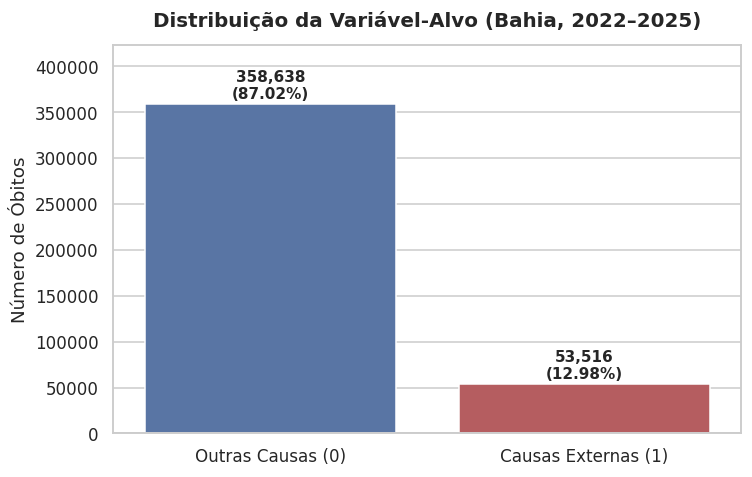

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))

contagem = df_eda["ALVO_LABEL"].value_counts()
total = len(df_eda)

sns.barplot(
    x=contagem.index,
    y=contagem.values,
    hue=contagem.index,
    palette=["#4C72B0", "#C44E52"],
    legend=False,
    ax=ax
)

for i, v in enumerate(contagem.values):
    pct = (v / total) * 100
    ax.text(i, v + (total * 0.015), f"{v:,}\n({pct:.2f}%)", ha="center", fontweight="bold", fontsize=10)

ax.set_title("Distribuição da Variável-Alvo (Bahia, 2022–2025)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("")
ax.set_ylabel("Número de Óbitos")
ax.set_ylim(0, contagem.max() * 1.18)
plt.tight_layout()
plt.show()

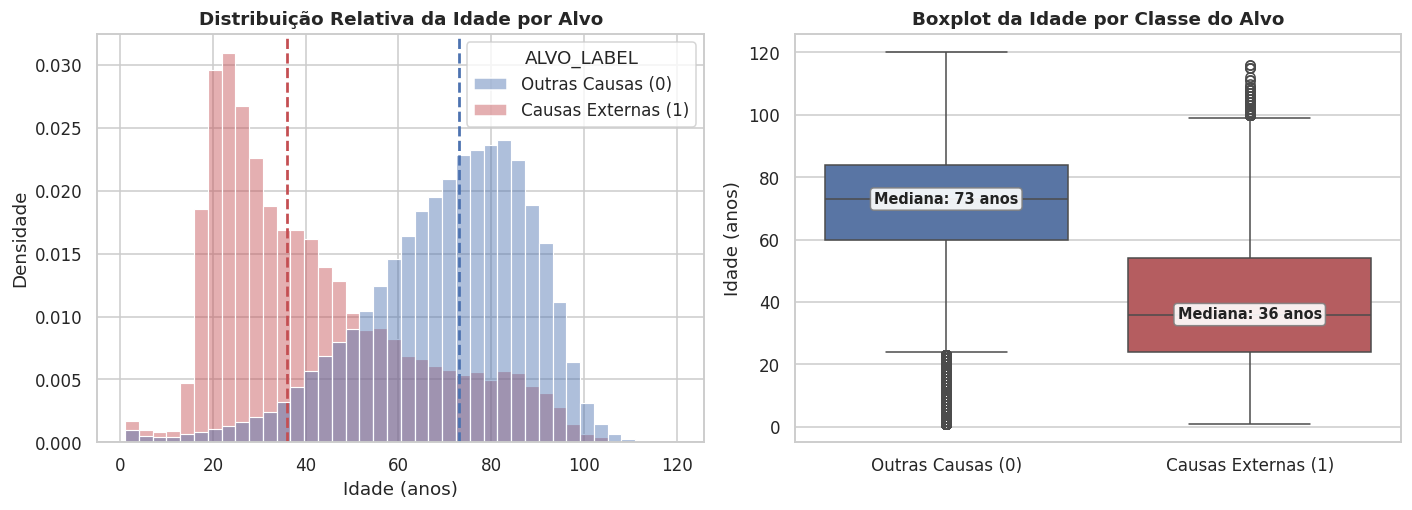

Medianas de idade por classe:
 - Outras Causas (0): 73.0 anos
 - Causas Externas (1): 36.0 anos


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Garantir que as variáveis necessárias estejam carregadas
if 'df_eda' not in locals():
    print("Variável 'df_eda' não encontrada. Recriando a partir do arquivo limpo...")
    try:
        df_limpo = pd.read_csv("sim_BA_2022_2025_limpo_pc3.csv", sep=",", dtype=str, low_memory=False)
    except FileNotFoundError:
        # Caso o arquivo esteja em outro local ou Drive
        caminho_alt = "/content/drive/MyDrive/Drive-Grupo02/sim_BA_2022_2025_base_estudo.csv.gz"
        df_limpo = pd.read_csv(caminho_alt, sep=",", dtype=str, low_memory=False)
        df_limpo = df_limpo.drop(columns=['CAUSABAS'], errors='ignore')

    # Re-aplicar tipos numéricos necessários para os gráficos
    df_limpo['IDADE_ANOS'] = df_limpo['IDADE_ANOS'].astype(float).astype(int)
    df_limpo['ALVO_CAUSA_EXTERNA'] = df_limpo['ALVO_CAUSA_EXTERNA'].astype(float).astype(int)

    # Recriar as labels amigáveis para plotagem
    df_eda = df_limpo.copy()
    map_alvo = {0: "Outras Causas (0)", 1: "Causas Externas (1)"}
    df_eda["ALVO_LABEL"] = df_eda["ALVO_CAUSA_EXTERNA"].map(map_alvo)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

ordem = ["Outras Causas (0)", "Causas Externas (1)"]
cores = {"Outras Causas (0)": "#4C72B0", "Causas Externas (1)": "#C44E52"}
medianas = df_eda.groupby("ALVO_LABEL")["IDADE_ANOS"].median()

# Esquerda: Distribuição de densidade/histograma
sns.histplot(
    data=df_eda,
    x="IDADE_ANOS",
    hue="ALVO_LABEL",
    hue_order=ordem,
    bins=40,
    stat="density",
    common_norm=False,
    alpha=0.45,
    palette=cores,
    ax=axes[0]
)

# Linhas verticais tracejadas marcando as medianas no histograma
for classe in ordem:
    med = medianas[classe]
    axes[0].axvline(med, color=cores[classe], linestyle="--", linewidth=1.8)

axes[0].set_title("Distribuição Relativa da Idade por Alvo", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Idade (anos)")
axes[0].set_ylabel("Densidade")

# Direita: Boxplot comparativo
sns.boxplot(
    data=df_eda,
    x="ALVO_LABEL",
    y="IDADE_ANOS",
    order=ordem,
    hue="ALVO_LABEL",
    hue_order=ordem,
    palette=cores,
    legend=False,
    ax=axes[1]
)

# Rótulo com o valor exato da mediana em cima de cada caixa
for i, classe in enumerate(ordem):
    med = medianas[classe]
    axes[1].text(
        i, med, f"Mediana: {med:.0f} anos",
        ha="center", va="center",
        fontweight="bold", fontsize=9.5, color="#222222",
        bbox=dict(facecolor="white", alpha=0.9, edgecolor="gray", boxstyle="round,pad=0.25")
    )

axes[1].set_title("Boxplot da Idade por Classe do Alvo", fontsize=12, fontweight="bold")
axes[1].set_xlabel("")
axes[1].set_ylabel("Idade (anos)")

plt.tight_layout()
plt.show()

# Imprime os valores exatos logo abaixo do gráfico
print("Medianas de idade por classe:")
for classe in ordem:
    print(f" - {classe}: {medianas[classe]:.1f} anos")

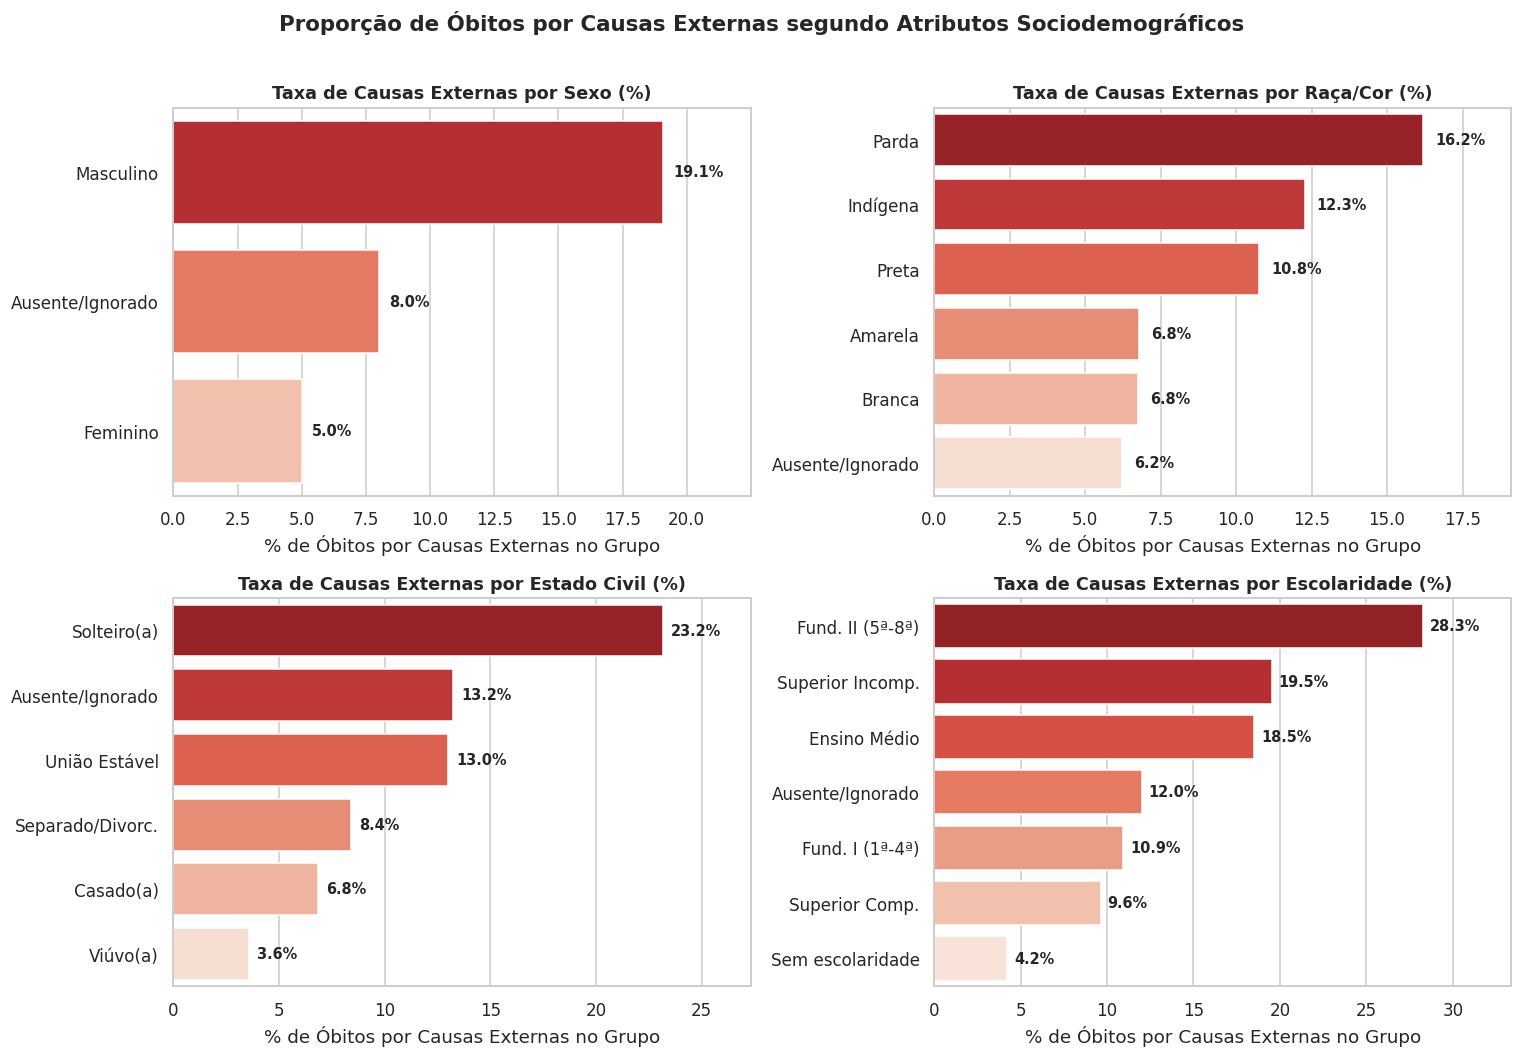

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))

variaveis = [
    ("SEXO_LABEL", "Taxa de Causas Externas por Sexo (%)", axes[0, 0]),
    ("RACACOR_LABEL", "Taxa de Causas Externas por Raça/Cor (%)", axes[0, 1]),
    ("ESTCIV_LABEL", "Taxa de Causas Externas por Estado Civil (%)", axes[1, 0]),
    ("ESC2010_LABEL", "Taxa de Causas Externas por Escolaridade (%)", axes[1, 1]),
]

for col, titulo, ax in variaveis:
    taxa = (df_eda.groupby(col)["ALVO_CAUSA_EXTERNA"].mean() * 100).sort_values(ascending=False)
    sns.barplot(
        x=taxa.values,
        y=taxa.index,
        hue=taxa.index,
        palette="Reds_r",
        legend=False,
        ax=ax
    )
    for i, v in enumerate(taxa.values):
        ax.text(v + 0.4, i, f"{v:.1f}%", va="center", fontsize=9.5, fontweight="bold")
    ax.set_title(titulo, fontsize=11.5, fontweight="bold")
    ax.set_xlabel("% de Óbitos por Causas Externas no Grupo")
    ax.set_ylabel("")
    ax.set_xlim(0, taxa.max() * 1.18)

plt.suptitle("Proporção de Óbitos por Causas Externas segundo Atributos Sociodemográficos", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

/tmp/ipykernel_2072/751614428.py:41: UserWarning: Glyph 135 (\x87) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2072/751614428.py:41: UserWarning: Glyph 130 (\x82) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 135 (\x87) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 130 (\x82) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


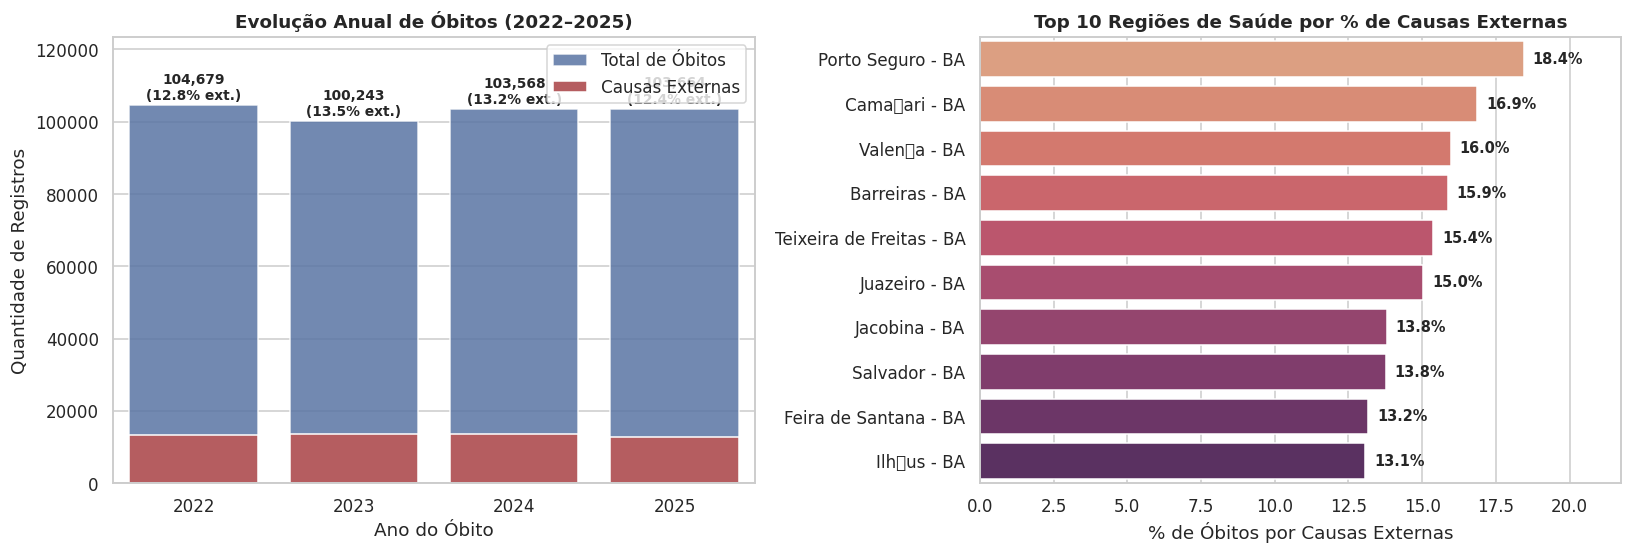

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

# Gráfico 4: Volume anual + taxa de causas externas
resumo_ano = df_eda.groupby("ANO_OBITO").agg(
    Total=("ALVO_CAUSA_EXTERNA", "count"),
    Causas_Externas=("ALVO_CAUSA_EXTERNA", "sum"),
    Taxa_Pct=("ALVO_CAUSA_EXTERNA", lambda x: x.mean() * 100)
).reset_index()

sns.barplot(data=resumo_ano, x="ANO_OBITO", y="Total", color="#4C72B0", alpha=0.85, ax=axes[0], label="Total de Óbitos")
sns.barplot(data=resumo_ano, x="ANO_OBITO", y="Causas_Externas", color="#C44E52", ax=axes[0], label="Causas Externas")

for i, row in resumo_ano.iterrows():
    axes[0].text(i, row["Total"] + 1500, f"{int(row['Total']):,}\n({row['Taxa_Pct']:.1f}% ext.)", ha="center", fontsize=9, fontweight="bold")

axes[0].set_title("Evolução Anual de Óbitos (2022–2025)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Ano do Óbito")
axes[0].set_ylabel("Quantidade de Registros")
axes[0].set_ylim(0, resumo_ano["Total"].max() * 1.18)
axes[0].legend()

# Gráfico 5: Top 10 Regiões de Saúde com maior % de Causas Externas
taxa_regiao = (df_eda.groupby("NO_REGSAUD")["ALVO_CAUSA_EXTERNA"].mean() * 100).sort_values(ascending=False).head(10)

sns.barplot(
    x=taxa_regiao.values,
    y=taxa_regiao.index,
    hue=taxa_regiao.index,
    palette="flare",
    legend=False,
    ax=axes[1]
)
for i, v in enumerate(taxa_regiao.values):
    axes[1].text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9.5, fontweight="bold")

axes[1].set_title("Top 10 Regiões de Saúde por % de Causas Externas", fontsize=12, fontweight="bold")
axes[1].set_xlabel("% de Óbitos por Causas Externas")
axes[1].set_ylabel("")
axes[1].set_xlim(0, taxa_regiao.max() * 1.18)

plt.tight_layout()
plt.show()

#### Exportação histórica da base limpa (registro da execução anterior)

A próxima célula foi preservada integralmente, **inclusive com a saída original do colega**. Ela gerava uma cópia local e podia utilizar um caminho pessoal de Drive; **não é necessária para continuar o PC3**. A publicação atual para o Drive compartilhado está no Passo 6.

In [ ]:
import os, shutil

PASTA_DRIVE = "/content/drive/MyDrive/Projeto_SIM_Grupo02"
nome_limpo = "sim_BA_2022_2025_limpo_pc3.csv"

df_limpo.to_csv(nome_limpo, index=False, sep=",", encoding="utf-8")
if os.path.exists(PASTA_DRIVE):
    shutil.copy(nome_limpo, os.path.join(PASTA_DRIVE, nome_limpo))
    print(f"✅ Base limpa salva no Colab e no Drive: {os.path.join(PASTA_DRIVE, nome_limpo)}")
else:
    print(f"✅ Base limpa salva localmente no Colab: /content/{nome_limpo}")

print(f"Dimensões entregues para os Passos 4, 5 e 6: {df_limpo.shape[0]:,} linhas x {df_limpo.shape[1]} colunas")

✅ Base limpa salva localmente no Colab: /content/sim_BA_2022_2025_limpo_pc3.csv
Dimensões entregues para os Passos 4, 5 e 6: 412,154 linhas x 9 colunas


### Principais Achados da Análise Exploratória (Passo 3)

1. **Desbalanceamento da Variável-Alvo:** A classe positiva (`Causas Externas = 1`) representa **12,98%** dos registros contra **87,02%** das demais causas. Esse desbalanceamento indica que a acurácia isolada será uma métrica enganosa na modelagem, tornando essencial avaliar os modelos com **Precisão, Recall, F1-score e ROC-AUC** (além de testar estratégias de ajuste de peso de classes).
2. **Forte poder discriminativo da Idade (`IDADE_ANOS`):** A mediana de idade em óbitos por causas externas é de **36 anos**, enquanto nas demais causas é de **73 anos**. A distribuição mostra que causas externas concentram-se fortemente em jovens adultos, tornando a idade um dos atributos mais promissores para a classificação.
3. **Diferenças no Perfil Sociodemográfico:** Observa-se uma proporção expressivamente maior de causas externas no sexo **[Masculino — 19.1% vs. Feminino — 5%]**, em indivíduos **solteiros — 23.2%** e em determinadas faixas de raça/cor e escolaridade. Além disso, a categoria `Ausente/Ignorado` em variáveis como **.: estado civil** apresentou taxa de **13.2%** de causas externas, reforçando a decisão de não descartar esses registros na limpeza.
4. **Comportamento Temporal e Territorial:** O volume de registros manteve-se ** estável ** ao longo do período 2022–2025, e há variação relevante entre as 28 Regiões de Saúde da Bahia (com destaque para **Porto Seguro, Camaçari e Valença**), justificando a inclusão do conjunto territorial M3 nos experimentos.

#### Exportação histórica das figuras (registro da execução anterior)

A célula a seguir também foi mantida **com todas as saídas originais**, para conservar o histórico do Passo 3. Não é necessário executá-la novamente: os gráficos já estão documentados no notebook e no repositório.

In [ ]:
import os
import shutil
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# Pasta de destino no Google Drive
PASTA_GRAFICOS = "/content/drive/MyDrive/Drive-Grupo02/"
os.makedirs(PASTA_GRAFICOS, exist_ok=True)

sns.set_theme(style="whitegrid", palette="muted")

def salvar_fig(fig, nome_arquivo):
    caminho = os.path.join(PASTA_GRAFICOS, nome_arquivo)
    fig.savefig(caminho, dpi=300, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    print(f"✅ Salvo: {caminho}")

# ---------------------------------------------------------
# 1. Distribuição da Variável-Alvo
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 4.5))
contagem = df_eda["ALVO_LABEL"].value_counts()
total = len(df_eda)

sns.barplot(
    x=contagem.index, y=contagem.values, hue=contagem.index,
    palette=["#4C72B0", "#C44E52"], legend=False, ax=ax
)
for i, v in enumerate(contagem.values):
    ax.text(i, v + (total * 0.015), f"{v:,}\n({(v/total)*100:.2f}%)", ha="center", fontweight="bold", fontsize=10)

ax.set_title("Distribuição da Variável-Alvo (Bahia, 2022–2025)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("")
ax.set_ylabel("Número de Óbitos")
ax.set_ylim(0, contagem.max() * 1.18)
plt.tight_layout()
salvar_fig(fig, "01_distribuicao_alvo.png")

# ---------------------------------------------------------
# 2. Idade por Alvo (Histograma + Boxplot com Medianas)
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ordem = ["Outras Causas (0)", "Causas Externas (1)"]
cores = {"Outras Causas (0)": "#4C72B0", "Causas Externas (1)": "#C44E52"}
medianas = df_eda.groupby("ALVO_LABEL")["IDADE_ANOS"].median()

sns.histplot(
    data=df_eda, x="IDADE_ANOS", hue="ALVO_LABEL", hue_order=ordem,
    bins=40, stat="density", common_norm=False, alpha=0.45, palette=cores, ax=axes[0]
)
for classe in ordem:
    axes[0].axvline(medianas[classe], color=cores[classe], linestyle="--", linewidth=1.8)
axes[0].set_title("Distribuição Relativa da Idade por Alvo", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Idade (anos)")
axes[0].set_ylabel("Densidade")

sns.boxplot(
    data=df_eda, x="ALVO_LABEL", y="IDADE_ANOS", order=ordem,
    hue="ALVO_LABEL", hue_order=ordem, palette=cores, legend=False, ax=axes[1]
)
for i, classe in enumerate(ordem):
    med = medianas[classe]
    axes[1].text(
        i, med, f"Mediana: {med:.0f} anos", ha="center", va="center",
        fontweight="bold", fontsize=9.5, color="#222222",
        bbox=dict(facecolor="white", alpha=0.9, edgecolor="gray", boxstyle="round,pad=0.25")
    )
axes[1].set_title("Boxplot da Idade por Classe do Alvo", fontsize=12, fontweight="bold")
axes[1].set_xlabel("")
axes[1].set_ylabel("Idade (anos)")
plt.tight_layout()
salvar_fig(fig, "02_idade_por_alvo.png")

# ---------------------------------------------------------
# 3. Painel 2x2 — Perfil Sociodemográfico
# ---------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))
variaveis = [
    ("SEXO_LABEL", "Taxa de Causas Externas por Sexo (%)", axes[0, 0]),
    ("RACACOR_LABEL", "Taxa de Causas Externas por Raça/Cor (%)", axes[0, 1]),
    ("ESTCIV_LABEL", "Taxa de Causas Externas por Estado Civil (%)", axes[1, 0]),
    ("ESC2010_LABEL", "Taxa de Causas Externas por Escolaridade (%)", axes[1, 1]),
]
for col, titulo, ax in variaveis:
    taxa = (df_eda.groupby(col)["ALVO_CAUSA_EXTERNA"].mean() * 100).sort_values(ascending=False)
    sns.barplot(x=taxa.values, y=taxa.index, hue=taxa.index, palette="Reds_r", legend=False, ax=ax)
    for i, v in enumerate(taxa.values):
        ax.text(v + 0.4, i, f"{v:.1f}%", va="center", fontsize=9.5, fontweight="bold")
    ax.set_title(titulo, fontsize=11.5, fontweight="bold")
    ax.set_xlabel("% de Óbitos por Causas Externas no Grupo")
    ax.set_ylabel("")
    ax.set_xlim(0, taxa.max() * 1.18)

plt.suptitle("Proporção de Óbitos por Causas Externas segundo Atributos Sociodemográficos", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
salvar_fig(fig, "03_perfil_sociodemografico.png")

# ---------------------------------------------------------
# 4. Evolução Anual + Top 10 Regiões de Saúde
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
resumo_ano = df_eda.groupby("ANO_OBITO").agg(
    Total=("ALVO_CAUSA_EXTERNA", "count"),
    Causas_Externas=("ALVO_CAUSA_EXTERNA", "sum"),
    Taxa_Pct=("ALVO_CAUSA_EXTERNA", lambda x: x.mean() * 100)
).reset_index()

sns.barplot(data=resumo_ano, x="ANO_OBITO", y="Total", color="#4C72B0", alpha=0.85, ax=axes[0], label="Total de Óbitos")
sns.barplot(data=resumo_ano, x="ANO_OBITO", y="Causas_Externas", color="#C44E52", ax=axes[0], label="Causas Externas")
for i, row in resumo_ano.iterrows():
    axes[0].text(i, row["Total"] + 1500, f"{int(row['Total']):,}\n({row['Taxa_Pct']:.1f}% ext.)", ha="center", fontsize=9, fontweight="bold")
axes[0].set_title("Evolução Anual de Óbitos (2022–2025)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Ano do Óbito")
axes[0].set_ylabel("Quantidade de Registros")
axes[0].set_ylim(0, resumo_ano["Total"].max() * 1.18)
axes[0].legend()

taxa_regiao = (df_eda.groupby("NO_REGSAUD")["ALVO_CAUSA_EXTERNA"].mean() * 100).sort_values(ascending=False).head(10)
sns.barplot(x=taxa_regiao.values, y=taxa_regiao.index, hue=taxa_regiao.index, palette="flare", legend=False, ax=axes[1])
for i, v in enumerate(taxa_regiao.values):
    axes[1].text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9.5, fontweight="bold")
axes[1].set_title("Top 10 Regiões de Saúde por % de Causas Externas", fontsize=12, fontweight="bold")
axes[1].set_xlabel("% de Óbitos por Causas Externas")
axes[1].set_ylabel("")
axes[1].set_xlim(0, taxa_regiao.max() * 1.18)
plt.tight_layout()
salvar_fig(fig, "04_evolucao_e_regioes.png")

# ---------------------------------------------------------
# 5. (Opcional) Baixar tudo compactado em .zip para o seu computador
# ---------------------------------------------------------
shutil.make_archive("/content/graficos_pc3", "zip", PASTA_GRAFICOS)
files.download("/content/graficos_pc3.zip")

✅ Salvo: /content/drive/MyDrive/Drive-Grupo02/01_distribuicao_alvo.png
✅ Salvo: /content/drive/MyDrive/Drive-Grupo02/02_idade_por_alvo.png
✅ Salvo: /content/drive/MyDrive/Drive-Grupo02/03_perfil_sociodemografico.png


/tmp/ipykernel_2738/926029325.py:127: UserWarning: Glyph 135 (\x87) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2738/926029325.py:127: UserWarning: Glyph 130 (\x82) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2738/926029325.py:15: UserWarning: Glyph 135 (\x87) missing from font(s) DejaVu Sans.
  fig.savefig(caminho, dpi=300, bbox_inches="tight", facecolor="white")
/tmp/ipykernel_2738/926029325.py:15: UserWarning: Glyph 130 (\x82) missing from font(s) DejaVu Sans.
  fig.savefig(caminho, dpi=300, bbox_inches="tight", facecolor="white")


✅ Salvo: /content/drive/MyDrive/Drive-Grupo02/04_evolucao_e_regioes.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## Passo 4 — Seleção e Auditoria dos Atributos

### Objetivo

Definir e auditar os conjuntos de variáveis preditoras para os experimentos de Aprendizado de Máquina, partindo **exclusivamente da base limpa produzida no Passo 2**. Os conjuntos M1, M2 e M3 foram definidos no PC2 e são preservados sem seleção oportunista baseada no desempenho dos classificadores.

### Conjuntos incrementais

| Conjunto | Atributos | Finalidade |
|---|---|---|
| **M1 — Básico** | `IDADE_ANOS`, `SEXO` | Referência demográfica. |
| **M2 — Sociodemográfico** | M1 + `RACACOR`, `ESTCIV`, `ESC2010` | Avaliar contribuição sociodemográfica adicional. |
| **M3 — Territorial** | M2 + `NO_REGSAUD` | Avaliar informação da Região de Saúde de residência. |

### Critérios

1. **Disponibilidade e integridade:** verificar presença, tipos, cardinalidade e ausências dos atributos após a limpeza do Passo 2.
2. **Comparação incremental:** M2 contém M1 e M3 contém M2, permitindo analisar o efeito da adição de informações.
3. **Separação de papéis:** `ALVO_CAUSA_EXTERNA` é a resposta da classificação binária; `ANO_OBITO` é controle temporal; `CODMUNRES` serve para rastreabilidade e não será preditor.
4. **Prevenção de vazamento:** `CAUSABAS`, que originou o alvo no PC2, e outros campos diretamente relacionados à causa do óbito não serão usados nos modelos.

A classificação identifica **perfis entre óbitos registrados**, não estima risco individual prospectivo de morrer por causa externa.


In [ ]:
import numpy as np
import pandas as pd
from IPython.display import display

# A fonte correta é df_limpo, gerado APÓS executar as três células do Passo 2.
if "df_limpo" not in globals() or "IDADE_ANOS" not in df_limpo.columns:
    raise RuntimeError("Execute as três células do Passo 2 antes do Passo 4.")

df_pc3 = df_limpo.copy()

CONJUNTOS = {
    "M1": ["IDADE_ANOS", "SEXO"],
    "M2": ["IDADE_ANOS", "SEXO", "RACACOR", "ESTCIV", "ESC2010"],
    "M3": ["IDADE_ANOS", "SEXO", "RACACOR", "ESTCIV", "ESC2010", "NO_REGSAUD"],
}
ALVO = "ALVO_CAUSA_EXTERNA"
TEMPO = "ANO_OBITO"

necessarias = set(CONJUNTOS["M3"]) | {ALVO, TEMPO, "CODMUNRES"}
faltantes = sorted(necessarias - set(df_pc3.columns))
assert not faltantes, f"Colunas ausentes: {faltantes}"

# Conversões necessárias para os modelos (sem alterações na base do Passo 2).
for coluna in ["IDADE_ANOS", TEMPO, ALVO]:
    df_pc3[coluna] = pd.to_numeric(df_pc3[coluna], errors="raise")

df_pc3[TEMPO] = df_pc3[TEMPO].astype(int)
df_pc3[ALVO] = df_pc3[ALVO].astype(int)

for coluna in ["SEXO", "RACACOR", "ESTCIV", "ESC2010", "NO_REGSAUD"]:
    # O SimpleImputer recebe np.nan em vez de pd.NA nas colunas object.
    df_pc3[coluna] = df_pc3[coluna].astype(object).where(df_pc3[coluna].notna(), np.nan)

assert df_pc3["IDADE_ANOS"].notna().all()
assert df_pc3["IDADE_ANOS"].between(0, 120).all()
assert df_pc3[TEMPO].isin([2022, 2023, 2024, 2025]).all()
assert set(df_pc3[ALVO].unique()) == {0, 1}

print("=== PASSO 4 — SELEÇÃO DOS ATRIBUTOS ===")
print(f"Registros na base limpa: {len(df_pc3):,}")
for nome, cols in CONJUNTOS.items():
    print(f"{nome} ({len(cols)} atributos): {', '.join(cols)}")

atributos = CONJUNTOS["M3"]
auditoria = pd.DataFrame({
    "Tipo": df_pc3[atributos].dtypes.astype(str),
    "Qtd_Nulos": df_pc3[atributos].isna().sum(),
    "Pct_Nulos (%)": (df_pc3[atributos].isna().mean() * 100).round(2),
    "Valores_Unicos": df_pc3[atributos].nunique(dropna=True),
})
display(auditoria)


=== PASSO 4 — SELEÇÃO DOS ATRIBUTOS ===
Registros na base limpa: 412,154
M1 (2 atributos): IDADE_ANOS, SEXO
M2 (5 atributos): IDADE_ANOS, SEXO, RACACOR, ESTCIV, ESC2010
M3 (6 atributos): IDADE_ANOS, SEXO, RACACOR, ESTCIV, ESC2010, NO_REGSAUD


,Tipo,Qtd_Nulos,Pct_Nulos (%),Valores_Unicos
IDADE_ANOS,int64,0,0.00,120
SEXO,object,25,0.01,2
RACACOR,object,11796,2.86,5
ESTCIV,object,41339,10.03,5
ESC2010,object,73807,17.91,6
NO_REGSAUD,object,0,0.00,28


### Justificativa da Seleção de Atributos (Passo 4)

1. **M1 — Básico:** idade e sexo constituem a referência inicial. As distribuições descritas no Passo 3 indicam diferenças no perfil dessas características entre óbitos por causas externas e demais causas.
2. **M2 — Sociodemográfico:** raça/cor, estado civil e escolaridade ampliam a caracterização dos registros. Seus valores ignorados ou ausentes serão preservados até o pré-processamento, sem descartar linhas por falta dessas informações.
3. **M3 — Territorial:** a Região de Saúde acrescenta contexto territorial às características individuais. O relacionamento utiliza a base territorial do PC2; sua referência temporal deverá constar como limitação metodológica.
4. **Critério comparativo:** os conjuntos foram definidos antes da avaliação dos modelos, evitando decidir a inclusão de variáveis com base no resultado do teste.
5. **Auditoria:** tipos, categorias distintas e ausências são verificados para confirmar que os três conjuntos podem ser usados pelo pipeline do Passo 6.

As diferenças encontradas nos registros do SIM são **associações descritivas**, não evidência de causalidade.


---
## Passo 5 — Prevenção de Vazamento de Dados e Separação Temporal

### Objetivo

Organizar a avaliação dos modelos de forma temporal e impedir o uso de informações indisponíveis ou diretamente relacionadas ao desfecho (*data leakage*).

A variável-alvo `ALVO_CAUSA_EXTERNA` foi criada no PC2 a partir de `CAUSABAS`. Logo, a própria causa básica, outros campos que revelem o desfecho, o ano de controle e os identificadores administrativos **não fazem parte das listas de preditores**.

### Particionamento

| Partição | Ano(s) | Uso |
|---|---|---|
| **Treino** | 2022–2023 | Ajuste inicial dos pré-processadores e modelos. |
| **Validação** | 2024 | Comparação dos conjuntos/modelos e ajuste de hiperparâmetros. |
| **Teste final** | 2025 | Avaliação única após as decisões de modelagem. |

O conjunto de teste permanece separado do ajuste e da seleção dos modelos. A condição **preliminar dos registros de 2025** deve ser mencionada na discussão das limitações, pois futuras versões do DATASUS podem apresentar diferenças.

Após escolher os modelos com a validação de 2024, o PC4 poderá **reajustar modelo e pré-processador com 2022–2024** antes de avaliar 2025 uma única vez. Não reutilizar o pré-processador ajustado apenas com 2022–2023 como se tivesse sido reajustado.


In [ ]:
# Apenas atributos explicitamente autorizados podem ser fornecidos aos modelos.
COLUNAS_VETADAS = {
    "CAUSABAS", "CAUSABAS_O", "ATESTADO", "LINHAA", "LINHAB",
    "LINHAC", "LINHAD", "LINHAII", "CIRCOBITO", "ACIDTRAB",
    "ANO_OBITO", "CODMUNRES", "ALVO_CAUSA_EXTERNA",
}

for nome, cols in CONJUNTOS.items():
    assert len(cols) == len(set(cols)), f"Colunas repetidas em {nome}"
    assert not (set(cols) & COLUNAS_VETADAS), f"Atributo vetado em {nome}"
    assert set(cols).issubset(df_pc3.columns), f"Atributo inexistente em {nome}"

assert set(CONJUNTOS["M1"]).issubset(CONJUNTOS["M2"])
assert set(CONJUNTOS["M2"]).issubset(CONJUNTOS["M3"])

# Índices únicos herdados da base; os três grupos são disjuntos.
particoes = {
    "treino": df_pc3.loc[df_pc3[TEMPO].isin([2022, 2023])].copy(),
    "validacao": df_pc3.loc[df_pc3[TEMPO].eq(2024)].copy(),
    "teste": df_pc3.loc[df_pc3[TEMPO].eq(2025)].copy(),
}

assert all(len(p) > 0 for p in particoes.values()), "Há partição temporal vazia"
assert sum(len(p) for p in particoes.values()) == len(df_pc3)
assert set(particoes["treino"].index).isdisjoint(particoes["validacao"].index)
assert set(particoes["treino"].index).isdisjoint(particoes["teste"].index)
assert set(particoes["validacao"].index).isdisjoint(particoes["teste"].index)

print("=== PASSO 5 — DIVISÃO TEMPORAL ===")
relatorio_particoes = pd.DataFrame([
    {
        "Particao": nome,
        "Anos": ", ".join(str(x) for x in sorted(parte[TEMPO].unique())),
        "Registros": len(parte),
        # A prevalência de 2025 será examinada somente no teste final do PC4.
        "Causas_Externas": int(parte[ALVO].sum()) if nome != "teste" else None,
        "Pct_Externas (%)": round(parte[ALVO].mean() * 100, 2) if nome != "teste" else None,
    }
    for nome, parte in particoes.items()
])
display(relatorio_particoes)


=== PASSO 5 — DIVISÃO TEMPORAL ===


,Particao,Anos,Registros,Causas_Externas,Pct_Externas (%)
0,treino,"2022, 2023",204922,26990.0,13.17
1,validacao,2024,103568,13660.0,13.19
2,teste,2025,103664,NaN,NaN


### Justificativa da Separação Temporal (Passo 5)

1. **Proteção contra vazamento:** os modelos recebem apenas os atributos M1, M2 ou M3; não recebem a variável que gerou o rótulo (`CAUSABAS`) nem os identificadores de controle.
2. **Avaliação em anos posteriores:** a separação cronológica evita misturar registros dos quatro anos no treinamento e no teste, permitindo verificar generalização temporal.
3. **Uso distinto das partições:** 2022–2023 servem ao treino, 2024 à seleção/validação e 2025 é reservado ao teste final.
4. **Separação do pré-processamento:** imputação, escala e categorias de codificação serão ajustadas somente no treino, conforme implementado no Passo 6.
5. **Desbalanceamento:** a distribuição do alvo deve ser considerada na seleção de métricas do PC4 (especialmente Precision, Recall, F1 e PR-AUC), sem recorrer à acurácia isolada.

A análise exploratória do Passo 3 já descreveu o período completo; por isso, a partição de 2025 não foi totalmente desconhecida em termos descritivos. O protocolo de modelagem deverá evitar ajustes em função dos resultados de 2025. Mudanças de cobertura ou completude dos dados do SIM também permanecem como limitações.


---
## Passo 6 — Pipelines de Pré-processamento e Exportação

### Objetivo

Preparar de forma consistente os conjuntos M1, M2 e M3 para o PC4, **sem ajustar parâmetros a partir de validação ou teste**, e publicar os resultados na pasta compartilhada do grupo.

### Transformações

| Tipo | Variáveis | Estratégia |
|---|---|---|
| Numérica | `IDADE_ANOS` | `SimpleImputer(strategy="median")` + `StandardScaler`. |
| Categórica | `SEXO`, `RACACOR`, `ESTCIV`, `ESC2010`, `NO_REGSAUD` (conforme M1/M2/M3) | Substituição de ausentes por `Ausente/Ignorado` + `OneHotEncoder(handle_unknown="ignore")`. |

Os pré-processadores de M1, M2 e M3 serão **ajustados em 2022–2023** e salvos como artefatos. O PC4 poderá usá-los para a comparação inicial e **deverá refazê-los** quando realizar o reajuste final em 2022–2024.

Os arquivos de treino, validação e teste serão exportados **ainda sem codificação numérica**, preservando as colunas originais, de modo que o pré-processamento possa ser integrado ao pipeline completo de cada algoritmo. Os arquivos usam o prefixo `pc3_v1` para distinguir a versão publicada. A exportação também inclui a base limpa e um manifesto de rastreabilidade.


In [ ]:
import joblib
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def construir_preprocessador(atributos):
    numericas = [col for col in atributos if col == "IDADE_ANOS"]
    categoricas = [col for col in atributos if col != "IDADE_ANOS"]

    num = Pipeline([
        ("imputacao", SimpleImputer(strategy="median")),
        ("padronizacao", StandardScaler()),
    ])
    cat = Pipeline([
        ("imputacao", SimpleImputer(strategy="constant", fill_value="Ausente/Ignorado")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore", dtype=np.float32)),
    ])
    return ColumnTransformer(
        [("numericas", num, numericas), ("categoricas", cat, categoricas)],
        remainder="drop",
        sparse_threshold=0.3,
    )

preprocessadores = {}
relatorio_preprocessamento = []
for nome, atributos in CONJUNTOS.items():
    modelo_preprocessamento = construir_preprocessador(atributos)
    X_treino = particoes["treino"][atributos]
    modelo_preprocessamento.fit(X_treino)  # fit APENAS 2022-2023

    # Teste pequeno de transformação; evita materializar a matriz completa.
    amostra = modelo_preprocessamento.transform(X_treino.head(10))
    amostra_array = amostra.toarray() if hasattr(amostra, "toarray") else amostra
    assert np.isfinite(amostra_array).all(), f"Transformação inválida em {nome}"

    preprocessadores[nome] = modelo_preprocessamento
    relatorio_preprocessamento.append({
        "Conjunto": nome,
        "Atributos_Originais": len(atributos),
        "Atributos_Codificados": len(modelo_preprocessamento.get_feature_names_out()),
        "Registros_Treino": len(X_treino),
    })

print("=== PASSO 6 — PIPELINES ===")
display(pd.DataFrame(relatorio_preprocessamento))
print("Pré-processadores ajustados exclusivamente com 2022–2023.")


=== PASSO 6 — PIPELINES ===


,Conjunto,Atributos_Originais,Atributos_Codificados,Registros_Treino
0,M1,2,4,204922
1,M2,5,23,204922
2,M3,6,51,204922


Pré-processadores ajustados exclusivamente com 2022–2023.


### Exportação para o Google Drive compartilhado

A célula a seguir salva **a base limpa**, as **três partições temporais**, os **pré-processadores M1/M2/M3** e um **manifesto JSON** na pasta compartilhada `Drive-Grupo02`, identificada por `PASTA_ID`.

Os arquivos são primeiro gerados localmente, depois enviados pela API do Google Drive já autenticada. Se um arquivo de mesmo nome **e mesmo conteúdo** já existir, seu envio é ignorado. Se houver mesmo nome com **conteúdo diferente**, a publicação é interrompida para evitar sobrescrever silenciosamente a versão do grupo (nesse caso, definir outra `VERSAO_SAIDA`).


In [ ]:
import hashlib
import json
from pathlib import Path

VERSAO_SAIDA = "pc3_v1"
PASTA_SAIDA = Path("/content/resultados_pc3")
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)


def hash_arquivo(caminho, algoritmo="sha256"):
    h = hashlib.new(algoritmo)
    with open(caminho, "rb") as arquivo:
        for bloco in iter(lambda: arquivo.read(1024 * 1024), b""):
            h.update(bloco)
    return h.hexdigest()


arquivos_saida = []

# 1. Base limpa: entrada reutilizável de PC3 para qualquer integrante.
arquivo_limpo = PASTA_SAIDA / "sim_BA_2022_2025_limpo_pc3.csv.gz"
df_limpo.to_csv(arquivo_limpo, index=False, compression={"method": "gzip", "mtime": 0}, encoding="utf-8")
arquivos_saida.append(arquivo_limpo)

# 2. Partições originais, sem One-Hot nem reescalonamento.
for nome, parte in particoes.items():
    caminho = PASTA_SAIDA / f"{VERSAO_SAIDA}_{nome}.csv.gz"
    parte.to_csv(caminho, index=False, compression={"method": "gzip", "mtime": 0}, encoding="utf-8")
    arquivos_saida.append(caminho)

# 3. Pré-processadores ajustados somente ao treino.
for nome, preprocessador in preprocessadores.items():
    caminho = PASTA_SAIDA / f"{VERSAO_SAIDA}_preprocessador_{nome}.joblib"
    joblib.dump(preprocessador, caminho)
    arquivos_saida.append(caminho)

# 4. Manifesto de rastreabilidade.
manifesto = {
    "projeto": "SIM-BA - Grupo 02",
    "etapa": "PC3 - Passos 4, 5 e 6",
    "versao": VERSAO_SAIDA,
    "entrada": NOME_PC2,
    "id_drive_entrada": arquivo_pc2["id"],
    "sha256_entrada": hash_arquivo(caminho_pc2),
    "alvo": ALVO,
    "conjuntos": CONJUNTOS,
    "periodos": {
        nome: {
            "anos": sorted(int(ano) for ano in parte[TEMPO].unique()),
            "registros": int(len(parte)),
        }
        for nome, parte in particoes.items()
    },
    "versao_sklearn": sklearn.__version__,
    "ajuste_preprocessadores": "2022-2023",
    "teste_final_reservado": "2025",
    "sha256_arquivos": {p.name: hash_arquivo(p) for p in arquivos_saida},
}
manifesto_path = PASTA_SAIDA / f"{VERSAO_SAIDA}_manifesto.json"
manifesto_path.write_text(json.dumps(manifesto, ensure_ascii=False, indent=2), encoding="utf-8")
arquivos_saida.append(manifesto_path)

# 5. Verificação de conflitos antes de iniciar qualquer upload.
atuais = {item["name"]: item for item in listar_arquivos(PASTA_ID)}
conflitos = [
    p.name for p in arquivos_saida
    if p.name in atuais and atuais[p.name].get("md5Checksum") != hash_arquivo(p, "md5")
]
if conflitos:
    raise FileExistsError(
        "Arquivos com o mesmo nome e conteúdo diferente no Drive: "
        + ", ".join(conflitos)
        + ". Revise a base ou altere VERSAO_SAIDA antes de publicar."
    )

# 6. Publicação idempotente para arquivos já existentes e idênticos.
print("=== PASSO 6 — PUBLICAÇÃO NO DRIVE COMPARTILHADO ===")
for caminho in arquivos_saida:
    if caminho.name in atuais:
        print("Já existe com mesmo conteúdo:", caminho.name)
        continue
    media = MediaFileUpload(str(caminho), resumable=True)
    resultado = drive_service.files().create(
        body={"name": caminho.name, "parents": [PASTA_ID]},
        media_body=media,
        fields="id,name",
        supportsAllDrives=True,
    ).execute()
    print("Publicado:", resultado["name"])

print("Concluído. Arquivos de PC3 disponíveis na pasta compartilhada.")


=== PASSO 6 — PUBLICAÇÃO NO DRIVE COMPARTILHADO ===
Publicado: sim_BA_2022_2025_limpo_pc3.csv.gz
Publicado: pc3_v1_treino.csv.gz
Publicado: pc3_v1_validacao.csv.gz
Publicado: pc3_v1_teste.csv.gz
Publicado: pc3_v1_preprocessador_M1.joblib
Publicado: pc3_v1_preprocessador_M2.joblib
Publicado: pc3_v1_preprocessador_M3.joblib
Publicado: pc3_v1_manifesto.json
Concluído. Arquivos de PC3 disponíveis na pasta compartilhada.


### Justificativa do Pré-processamento e da Persistência (Passo 6)

1. **Imputação numérica pela mediana:** reduz a sensibilidade a valores extremos em eventuais ausências de `IDADE_ANOS`. A base do Passo 2 já exclui idades inválidas, mas o pipeline preserva uma regra explícita para dados futuros.
2. **Padronização numérica:** o `StandardScaler` é pertinente para métodos sensíveis à escala, incluindo KNN, Regressão Logística regularizada e MLP.
3. **Categoria explícita para ausências:** manter `Ausente/Ignorado` evita descartar óbitos por ausência de informação sociodemográfica; não implica que ausência tenha interpretação causal.
4. **Codificação One-Hot:** converte categorias para atributos numéricos sem atribuir ordem artificial aos códigos do SIM.
5. **Ajuste apenas no treino:** medianas, médias, desvios e categorias são aprendidos em 2022–2023. A validação de 2024 e o teste de 2025 não participam de seu ajuste inicial.
6. **Artefatos reutilizáveis:** os CSVs comprimidos, pré-processadores e o manifesto permitem que o PC4 utilize os mesmos dados, sem repetir PC2 e Passos 1–3. Os hashes e a identificação da fonte ajudam na auditoria de versões.
